# PlantaIa — Tarea 2: clasificador en la ESP32

Este notebook implementa y compara los clasificadores de la Tarea 2 y elige el que va a la placa. El contrato (features, target, protocolo, criterio de selección) es [`docs/ENTREGA2.md`](../docs/ENTREGA2.md); el código compartido está en `ml/plantaia_ml/` y el modelo exportado en `firmware/lib/plantaia_ml/modelo_plantaia.h`.

**Qué datos se usan.** Hay una sola maceta, `maceta-01`. Sus mediciones reales (12/09 al 21/10) tienen huecos de hasta 15 días y muy pocos episodios de etiqueta utilizables; el notebook 02 mostró que con eso un modelo no generaliza (5 % de exactitud balanceada por episodio). Los huecos se completaron **localmente** con un simulador calibrado con lo medido (`data/sintetico/`, fuera del repo; ver su README y `docs/entrega2/AUDITORIA_DATOS.md`). Cada fila lleva la marca `fuente`:

* `real`: lo midió la placa;
* `simulada_relleno`: la generó el simulador.

La marca sirve para lo más importante de este notebook: **no medir el modelo sólo contra datos que generó el propio simulador**. La §6 evalúa sobre las filas reales.

Para no volcar el relleno al repo, el notebook muestra sólo agregados y figuras de las filas simuladas, nunca filas sueltas. Para re-ejecutarlo hace falta el complemento local; sin él, `serie_maceta01()` devuelve sólo lo real.

**Re-ejecución.** El código no tiene números fijos: si se reemplaza el relleno, se vuelve a correr tal cual (`jupyter nbconvert --to notebook --execute --inplace notebooks/03_modelos.ipynb`). La §5.5 avisa si la selección ya no coincide con `CONFIG_FINAL` o si el header exportado quedó viejo, y la §7 reescribe `docs/entrega2/tablas_03_modelos.md` con todas las tablas. Los comentarios en texto describen la ejecución commiteada: la final, con el relleno **v2** (la fecha del relleno se imprime abajo).

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.patches import Patch
from scipy import stats
from sklearn.base import clone
from sklearn.metrics import (balanced_accuracy_score, confusion_matrix, f1_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.tree import export_text, plot_tree

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ml" / "plantaia_ml").is_dir())
sys.path.insert(0, str(RAIZ / "ml"))

from plantaia_ml import CLASES, FIGURAS
from plantaia_ml import dataset as _dataset
from plantaia_ml.dataset import serie_maceta01
from plantaia_ml.datos_reales import EPISODIOS_DUDOSOS
from plantaia_ml.exportar_c import RUTA_MODELO, version_modelo
from plantaia_ml.features import FEATURES
from plantaia_ml.modelos import (CONFIG_FINAL, K_EXTERNO, K_INTERNO, NOMBRE_SUBCONJUNTO,
                                 SUBCONJUNTOS, baselines, busqueda, candidatos, costo_esp32,
                                 modelo_final, particion_externa, particion_interna)

warnings.filterwarnings("ignore", category=FutureWarning)
from sklearn.exceptions import FitFailedWarning
# §6.1: con pocos episodios reales algunos folds internos quedan con una sola clase; esas
# configuraciones se puntúan NaN (se avisa en la celda) en vez de cortar la ejecución.
warnings.filterwarnings("ignore", category=FitFailedWarning)
warnings.filterwarnings("ignore", category=UserWarning)           # f1 con clases ausentes en un fold
warnings.filterwarnings("ignore", message=".*ill-defined.*")
warnings.filterwarnings("ignore", message=".*Stochastic Optimizer.*")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
FIGURAS.mkdir(parents=True, exist_ok=True)
SALIDA_TABLAS = RAIZ / "docs" / "entrega2" / "tablas_03_modelos.md"

# De dónde sale el relleno simulado (para saber con cuál se ejecutó el notebook). No hay
# números fijos en el código: si se reemplaza el relleno, se re-ejecuta tal cual.
_rutas_relleno = [getattr(_dataset, n) for n in ("RUTA_PAYLOADS", "RUTA_COMPLEMENTO") if hasattr(_dataset, n)]
_ruta = next((r for r in _rutas_relleno if r.exists()), None)
RELLENO_INFO = ("sin relleno local (sólo reales)" if _ruta is None else
                f"{_ruta.relative_to(RAIZ)} ({pd.Timestamp(_ruta.stat().st_mtime, unit='s', tz='UTC'):%Y-%m-%d %H:%M} UTC)")
print("relleno:", RELLENO_INFO)

COLORES = {"saludable": "#4c9f70", "estresada": "#e6a23c", "marchita": "#c84b4b"}
CODIGOS = [1, 2, 3]
FUENTES = {"real": "real (placa)", "simulada_relleno": "relleno simulado"}


def guardar(fig, nombre):
    fig.savefig(FIGURAS / nombre, dpi=150, bbox_inches="tight")
    print(f"figura: docs/entrega2/fig/{nombre}")

relleno: data/sintetico/payloads_relleno.jsonl (2026-10-21 23:41 UTC)


## 1. Datos

`serie_maceta01()` arma la serie completa de la maceta a 5 min: remuestrea el dato real (que quedó a 30 s) con la mediana por bin, cruza cada fila con su episodio de `data/episodios.csv` (o de `episodios_relleno.csv` en el relleno), calcula las features como las calcularía la placa y recién después filtra: fuera los primeros 60 min tras cada arranque (transitorio de la sonda), la sonda saturada, las filas sin vector completo y las que no caen en ningún episodio.

In [2]:
df = serie_maceta01()
X = df[FEATURES].to_numpy(np.float32)      # float32, como la placa y como sklearn recorre los árboles
y = df.clase_codigo.to_numpy(int)
g = df.episodio_id.to_numpy(int)
es_real = (df.fuente == "real").to_numpy()
dudoso = df.dudoso.to_numpy(bool)

print(f"filas: {len(df):,} · episodios: {df.episodio_id.nunique()} · "
      f"desde {df.ts.min():%d/%m %H:%M} hasta {df.ts.max():%d/%m %H:%M} UTC")
print(f"filas reales: {es_real.sum():,} ({es_real.mean():.1%}) · "
      f"episodios con al menos una fila real: {df[es_real].episodio_id.nunique()}")
mixtos = df.groupby("episodio_id").fuente.nunique()
print(f"episodios con filas de las dos fuentes (huecos chicos rellenados dentro de un episodio real): "
      f"{sorted(mixtos[mixtos > 1].index.tolist())}")

def conteos(d):
    return pd.Series({"filas": len(d), "episodios": d.episodio_id.nunique()})


filas_conteo = {}
for c in CLASES + ["total"]:
    dc = df if c == "total" else df[df.clase == c]
    fila = {}
    for f in ["real", "simulada_relleno"]:
        for k, v in conteos(dc[dc.fuente == f]).items():
            fila[(FUENTES[f], k)] = v
    for k, v in conteos(dc).items():
        fila[("serie completa", k)] = v
    filas_conteo[c] = fila
tabla_conteo = pd.DataFrame(filas_conteo).T
display(tabla_conteo)
print("proporción de filas por clase:", (df.clase.value_counts(normalize=True).reindex(CLASES)
                                         .round(3).to_dict()))

filas: 11,051 · episodios: 47 · desde 13/09 00:55 hasta 21/10 21:20 UTC
filas reales: 1,321 (12.0%) · episodios con al menos una fila real: 11
episodios con filas de las dos fuentes (huecos chicos rellenados dentro de un episodio real): [1, 3, 6, 8, 9, 10, 12, 13, 14]


real (placa)           relleno simulado           serie completa          
                 filas episodios            filas episodios          filas episodios
saludable          423         3             5178        10           5601        12
estresada          576         5             2112        20           2688        20
marchita           322         3             2440        15           2762        15
total             1321        11             9730        45          11051        47

proporción de filas por clase: {'saludable': 0.507, 'estresada': 0.243, 'marchita': 0.25}


Las filas son muchas pero **no son independientes**: dentro de un episodio todas comparten etiqueta y las contiguas están a 5 min. El N que importa para todo lo que sigue es el de **episodios**. Los episodios reales utilizables son pocos y casi todos de octubre.

Tabla de los episodios reales (agregados por episodio; los dudosos son los de `EPISODIOS_DUDOSOS`, con el motivo en `data/episodios.csv`):

In [3]:
reales_ep = (df[es_real].groupby("episodio_id")
             .agg(clase=("clase", "first"), origen=("etiqueta_origen", "first"),
                  dudoso=("dudoso", "first"), filas=("ts", "size"),
                  desde=("ts", "min"), suelo_mv_mediana=("suelo_mv", "median"),
                  temp_c_mediana=("temp_c", "median"), luz_mv_mediana=("luz_mv", "median")))
reales_ep["desde"] = reales_ep.desde.dt.strftime("%d/%m %H:%M")
display(reales_ep)
for k, v in EPISODIOS_DUDOSOS.items():
    print(f"dudoso {k}: {v}")

,clase,origen,dudoso,filas,desde,suelo_mv_mediana,temp_c_mediana,luz_mv_mediana
episodio_id,,,,,,,,
1,marchita,corregida,False,131,13/09 00:55,"2,832.000",8.500,189.000
3,estresada,manual,False,23,15/09 13:35,"2,769.500",34.200,"2,037.500"
6,estresada,manual,False,69,16/09 17:55,"2,050.000",14.400,"2,782.000"
8,marchita,manual,True,105,01/10 01:40,"1,512.000",20.600,142.000
9,estresada,manual,True,51,01/10 10:55,"1,454.000",19.000,"2,298.500"
10,saludable,manual,False,137,02/10 01:55,"1,504.000",18.600,"1,978.000"
11,saludable,propagada,True,27,19/10 00:35,"1,785.500",20.200,142.000
12,marchita,manual,False,86,19/10 02:50,"1,758.000",20.200,142.000
13,estresada,manual,False,136,19/10 10:20,"1,929.750",19.400,"1,666.750"


dudoso 8: marchita con el sustrato igual que saludable (~1550 mV), nocturna
dudoso 9: estresada con el sustrato en ~1454 mV, el rango de los saludable de octubre
dudoso 11: propagada de Preferences 16 días después; contradicha por la observación siguiente
dudoso 14: estresada propagada ~25 h después de un riego, sin nadie que la confirme


figura: docs/entrega2/fig/serie_maceta01_modelado.png


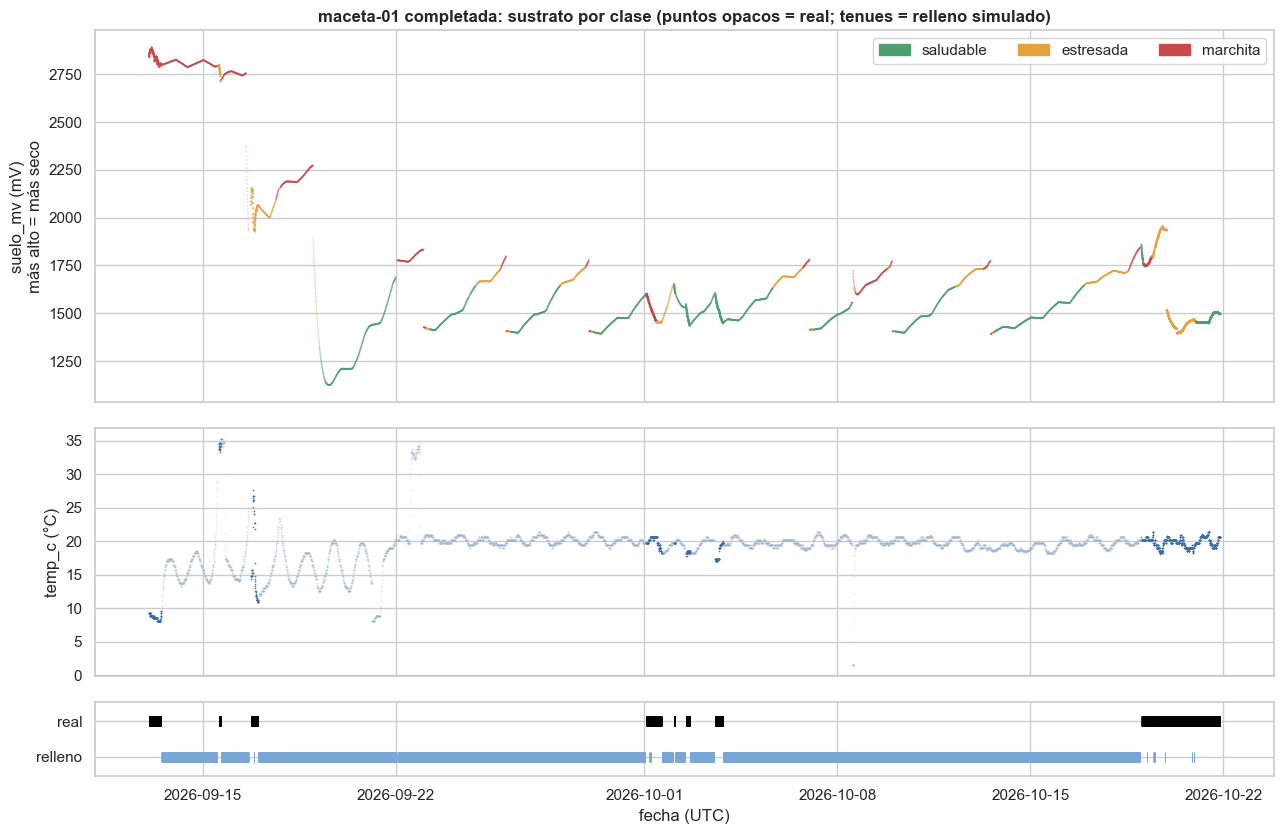

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(13, 8.5), sharex=True,
                         gridspec_kw={"height_ratios": [3, 2, 0.6]})
ax = axes[0]
for f, marca, alfa, tam in [("simulada_relleno", "o", 0.25, 1.5), ("real", "o", 0.9, 2.5)]:
    d = df[df.fuente == f]
    ax.scatter(d.ts, d.suelo_mv, s=tam, c=d.clase.map(COLORES), alpha=alfa, lw=0, rasterized=True)
ax.set_ylabel("suelo_mv (mV)\nmás alto = más seco")
ax.set_title("maceta-01 completada: sustrato por clase (puntos opacos = real; tenues = relleno simulado)",
             fontweight="bold")
ax.legend(handles=[Patch(color=COLORES[c], label=c) for c in CLASES], ncol=3, loc="upper right")
ax = axes[1]
for f, alfa in [("simulada_relleno", 0.25), ("real", 0.9)]:
    d = df[df.fuente == f]
    ax.scatter(d.ts, d.temp_c, s=1.5, c="#3a6ea5" if f == "real" else "#9bb7d4", alpha=alfa, lw=0,
               rasterized=True)
ax.set_ylabel("temp_c (°C)")
ax = axes[2]
for f, y0, col in [("real", 0.55, "black"), ("simulada_relleno", 0.0, "#7aa6d6")]:
    d = df[df.fuente == f]
    ax.scatter(d.ts, np.full(len(d), y0 + 0.2), marker="|", s=60, c=col, lw=0.6, rasterized=True)
ax.set_yticks([0.2, 0.75], ["relleno", "real"])
ax.set_ylim(-0.1, 1.05)
ax.set_xlabel("fecha (UTC)")
fig.tight_layout()
guardar(fig, "serie_maceta01_modelado.png")
plt.show()

**Lo que se ve** (ejecución con el relleno v2).

- **Dónde hay dato real.** La serie real ocupa pocas ventanas: 12–17/09, 1–3/10 y 18–21/10. El relleno cubre el resto con ciclos de secado → riego. Lo real es el 12 % de las filas y 11 de los 47 episodios.
- **La escala de la sonda se corre entre meses.** En septiembre la `marchita` real marcaba ~2830 mV. En octubre la marchita observada con el botón (ep. 12) está en ~1758 mV, por debajo de la mediana de la `estresada` del día siguiente (ep. 13, ~1930 mV).
- **Cómo se calibró el relleno v2.** Para octubre usa una curva anclada en lo medido (marchita desde ~1745 mV, lo más seco ~1960 mV). Ninguna fila simulada de octubre pasa del máximo real del mes.
- **Episodios perdidos.** El corte de 60 min tras cada arranque elimina enteros algunos episodios reales cortos de septiembre (`AUDITORIA_DATOS.md`, H7).

## 2. Preparación, features y target

**Features** (contrato §4, mismo código en Python y en C, con test de paridad): se calculan cada 5 min con la muestra actual y un buffer de 13 muestras (1 h). La placa arma siempre los 7 en este orden; si el modelo usa menos, el exportador remapea índices.

| idx | feature | qué es |
|---|---|---|
| 0 | `suelo_mv` | sonda resistiva, mediana de 9 (mV; más alto = más seco) |
| 1 | `suelo_delta_1h` | `suelo_mv(t) − suelo_mv(t−1 h)`; 0 en warm-up |
| 2 | `temp_c` | DHT11 (último válido si falla) |
| 3 | `hum_aire_pct` | DHT11 |
| 4 | `vpd_kpa` | déficit de presión de vapor (Tetens) con 2 y 3 |
| 5 | `luz_mv` | LDR, mediana de 9 |
| 6 | `luz_media_1h` | media de `luz_mv` en la última hora |

**Fuera a propósito**: la hora del día (en el dato real está confundida con el horario del observador, §6.4), `luz_pct`/`suelo_pct` (sin calibrar) y el termistor (su conversión en el firmware 1.1.0 está invertida).

**Target**: códigos del firmware 1 `saludable`, 2 `estresada`, 3 `marchita`. `sin_etiquetar` (0) no es clase: las filas sin episodio ya quedaron afuera en el filtrado. Las filas de warm-up (primera hora de cada tramo) **se quedan**: la placa también infiere en esa hora, con `suelo_delta_1h = 0`.

In [5]:
assert set(np.unique(y)) == {1, 2, 3}, "el target tiene que ser exactamente 1..3"
assert not df.clase.isin(["sin_etiquetar"]).any() and df.episodio_id.notna().all()
assert np.isfinite(X).all(), "no puede haber NaN en el vector (la placa no infiere sin vector completo)"
print(f"filas en warm-up (suelo_delta_1h = 0): {df.warmup.sum():,} ({df.warmup.mean():.1%})")

resumen = (df.groupby(["clase", "fuente"])[FEATURES].median().unstack("fuente")
           .reindex(CLASES).T)
resumen.index = [f"{f} · {FUENTES[s]}" for f, s in resumen.index]
print("Mediana de cada feature por clase y fuente:")
display(resumen)

filas en warm-up (suelo_delta_1h = 0): 144 (1.3%)
Mediana de cada feature por clase y fuente:


clase,saludable,estresada,marchita
suelo_mv · real (placa),"1,480.000","1,462.750","1,769.500"
suelo_mv · relleno simulado,"1,476.500","1,690.000","2,121.500"
suelo_delta_1h · real (placa),-2.000,2.000,-10.250
suelo_delta_1h · relleno simulado,4.500,3.500,3.000
temp_c · real (placa),19.800,19.400,20.200
temp_c · relleno simulado,19.800,19.800,19.000
hum_aire_pct · real (placa),48.000,46.000,50.000
hum_aire_pct · relleno simulado,47.000,47.000,47.500
vpd_kpa · real (placa),1.201,1.226,1.184
vpd_kpa · relleno simulado,1.224,1.217,1.121


**Lectura de las medianas.**

- **Relleno v2.** `suelo_mv` ordena las clases (saludable < estresada < marchita) y la luz ya no está invertida: las tres clases tienen luz parecida.
- **Real.** La marchita es nocturna (142 mV = oscuridad del LDR) y la `estresada` tiene el sustrato de una saludable, por los episodios dudosos 9 y 14.
- **Delta.** `suelo_delta_1h` sigue distinto entre fuentes: lo real deriva hacia abajo por los transitorios post-arranque, que el relleno no tiene.

Las búsquedas casi nunca eligen las features de luz y temperatura (§4), y el modelo final usa sólo `suelo_mv`.

## 3. Protocolo de evaluación

* **Partición externa por episodio**: `StratifiedGroupKFold` con k = 5 y `episodio_id` como grupo. Un episodio entero cae en train o en test, nunca partido. Es `GroupKFold` repartiendo los episodios para que cada fold tenga las tres clases (con `GroupKFold` a secas un fold se queda sin `marchita` y el recall de esa clase no se puede medir ahí).
* **Búsqueda de hiperparámetros anidada**: dentro de cada fold externo, `GridSearchCV` con otra partición por episodio (k = 3) sobre el train, maximizando F1 macro. El subconjunto de features es un hiperparámetro más (`suelo`, `suelo+delta`, `sin luz`, `todas`). El fold externo no participa de la elección.
* **Métricas por fold** y luego media ± desvío: exactitud balanceada (el azar con 3 clases es 0,33), F1 macro, recall de `marchita` (el error caro es no avisar) y ROC-AUC OvR cuando el modelo da probabilidades. Las matrices de confusión suman las predicciones fuera de fold de los 5 folds.

### ¿Por qué no un split aleatorio?

Las filas contiguas comparten etiqueta y son casi iguales. Con un split aleatorio, cada fila de test tiene a su vecina de 5 min en train: el modelo puede "reconocer el episodio" en vez de la condición de la planta. Mismo modelo y mismos datos, dos particiones:

In [6]:
from sklearn.ensemble import RandomForestClassifier


def bosque_todas():
    # Random Forest con las 7 features, sin búsqueda: el más capaz de memorizar episodios.
    return candidatos()["Random Forest"][0].set_params(sel__columnas=SUBCONJUNTOS["todas"],
                                                       clf__max_depth=8, clf__min_samples_leaf=20)


def comparar_particiones(est, X_, y_, g_):
    out = {}
    for nombre, cv, grupos in [("aleatoria (filas mezcladas)",
                                StratifiedKFold(K_EXTERNO, shuffle=True, random_state=0), None),
                               ("por episodio", particion_externa(), g_)]:
        ba = []
        for tr, te in cv.split(X_, y_, grupos):
            p = clone(est).fit(X_[tr], y_[tr]).predict(X_[te])
            ba.append(balanced_accuracy_score(y_[te], p))
        out[nombre] = f"{np.mean(ba):.3f} ± {np.std(ba):.3f}"
    return out


fuga = pd.DataFrame({
    "serie completa · RF 7 features": comparar_particiones(bosque_todas(), X, y, g),
    "sólo reales · RF 7 features": comparar_particiones(bosque_todas(), X[es_real], y[es_real], g[es_real]),
}).T
fuga.columns.name = "exactitud balanceada (5 folds)"
display(fuga)

exactitud balanceada (5 folds),aleatoria (filas mezcladas),por episodio
serie completa · RF 7 features,0.887 ± 0.009,0.681 ± 0.133
sólo reales · RF 7 features,0.947 ± 0.012,0.291 ± 0.356


**La fuga es grande.** El mismo Random Forest pasa de 0,887 de exactitud balanceada con filas mezcladas a 0,681 por episodio en la serie completa. En los reales solos pasa de 0,947 a 0,291, por debajo del azar y con un desvío enorme: es el hallazgo del notebook 02, que se sostiene con los episodios nuevos.

Todo lo que sigue usa partición por episodio. El N efectivo es el número de episodios, no el de filas.

## 4. Baselines y candidatos

**Baselines obligatorios** (sin búsqueda; se ajustan en el train de cada fold):

* *Clase mayoritaria*: siempre `saludable`.
* *Umbral único sobre `suelo_mv`*: un tocón (árbol de profundidad 1). Con un solo corte predice como mucho dos clases: es el baseline literal del plan.
* *Dos umbrales sobre `suelo_mv`*: la regla ordinal que pondría alguien mirando el histograma (`suelo ≤ t1` saludable, `≤ t2` estresada, si no marchita), con t1 y t2 elegidos en el train por F1 macro. Es el rival honesto: cualquier modelo que no le gane no justifica su complejidad.

**Candidatos** (§5.2, grillas en `ml/plantaia_ml/modelos.py`): regresión logística, árbol de decisión (prof. ≤ 8), Random Forest (30 árboles, prof. ≤ 8), Naive Bayes gaussiano, k-NN, SVM RBF y MLP chico. `class_weight="balanced"` donde existe (hay ~2 filas `saludable` por cada `marchita`).

In [7]:
def recall_marchita(y_, p_):
    return recall_score(y_, p_, labels=[3], average="macro", zero_division=0)


def metricas(y_, p_, proba_=None):
    m = {"exactitud_bal": balanced_accuracy_score(y_, p_),
         "f1_macro": f1_score(y_, p_, labels=CODIGOS, average="macro", zero_division=0),
         "recall_marchita": recall_marchita(y_, p_),
         "roc_auc_ovr": np.nan}
    if proba_ is not None and len(np.unique(y_)) == 3 and np.isfinite(proba_).all():
        m["roc_auc_ovr"] = roc_auc_score(y_, proba_, multi_class="ovr", average="macro", labels=CODIGOS)
    return m


def proba_3(modelo, X_):
    # predict_proba con las columnas 1..3 aunque el train no haya visto alguna clase.
    try:
        p = modelo.predict_proba(X_)
    except AttributeError:
        return None
    out = np.zeros((len(X_), 3))
    for j, c in enumerate(modelo.classes_):
        out[:, CODIGOS.index(int(c))] = p[:, j]
    return out


def evaluar(est, grilla, X_, y_, g_, cv=None, n_jobs=-1, tolerante=False):
    # Evaluación por episodio; con grilla, búsqueda anidada. Devuelve métricas por fold y predicciones fuera de fold.
    cv = cv or particion_externa()
    folds, elegidos = [], []
    oof = np.zeros(len(y_), int)
    oof_p = np.full((len(y_), 3), np.nan)
    for tr, te in cv.split(X_, y_, g_):
        if grilla:
            b = busqueda(est, grilla, n_jobs=n_jobs)
            if tolerante:   # con pocos episodios un fold interno puede quedar con una sola clase
                b.set_params(error_score=np.nan)
            b = b.fit(X_[tr], y_[tr], groups=g_[tr])
            modelo = b.best_estimator_
            elegidos.append(b.best_params_)
        else:
            modelo = clone(est).fit(X_[tr], y_[tr])
            elegidos.append({})
        oof[te] = modelo.predict(X_[te])
        p = proba_3(modelo, X_[te])
        if p is not None:
            oof_p[te] = p
        folds.append(metricas(y_[te], oof[te], p))
    return {"folds": pd.DataFrame(folds), "oof": oof, "oof_p": oof_p, "elegidos": elegidos}


def resumir(res):
    f = res["folds"]
    return {f"{k} (media)": f[k].mean() for k in f} | {f"{k} (desvío)": f[k].std(ddof=0) for k in f}


MODELOS = {**baselines(), **candidatos()}
ES_BASELINE = {n: n in baselines() for n in MODELOS}
resultados, tiempos = {}, {}
for nombre, (est, grilla) in MODELOS.items():
    t0 = time.perf_counter()
    resultados[nombre] = evaluar(est, grilla, X, y, g)
    tiempos[nombre] = time.perf_counter() - t0
    print(f"{nombre:<26} {tiempos[nombre]:6.1f} s")

Clase mayoritaria             0.0 s
Umbral único (suelo_mv)       0.0 s


Dos umbrales (suelo_mv)       0.3 s


Regresión logística           4.0 s


Árbol de decisión             0.7 s


Random Forest                 2.9 s
Naive Bayes                   0.1 s


k-NN                          1.9 s


SVM RBF                      15.7 s


MLP                           9.4 s


In [8]:
METRICAS = ["exactitud_bal", "f1_macro", "recall_marchita", "roc_auc_ovr"]


def tabla_metricas(res_por_modelo):
    filas = {}
    for n, r in res_por_modelo.items():
        f = r["folds"]
        filas[n] = {m: f"{f[m].mean():.3f} ± {f[m].std(ddof=0):.3f}" if f[m].notna().all() else "n/d"
                    for m in METRICAS}
    return pd.DataFrame(filas).T


print(f"Serie completa · {df.episodio_id.nunique()} episodios · StratifiedGroupKFold k={K_EXTERNO} "
      f"(media ± desvío entre folds)")
tabla_cv = tabla_metricas(resultados)
display(tabla_cv)

resumen_cv = pd.DataFrame({n: resumir(r) for n, r in resultados.items()}).T

Serie completa · 47 episodios · StratifiedGroupKFold k=5 (media ± desvío entre folds)


,exactitud_bal,f1_macro,recall_marchita,roc_auc_ovr
Clase mayoritaria,0.333 ± 0.000,0.232 ± 0.036,0.000 ± 0.000,0.500 ± 0.000
Umbral único (suelo_mv),0.601 ± 0.060,0.523 ± 0.058,0.823 ± 0.183,0.760 ± 0.089
Dos umbrales (suelo_mv),0.751 ± 0.118,0.749 ± 0.123,0.811 ± 0.184,n/d
Regresión logística,0.623 ± 0.147,0.615 ± 0.162,0.421 ± 0.265,0.836 ± 0.067
Árbol de decisión,0.733 ± 0.133,0.712 ± 0.180,0.776 ± 0.171,0.818 ± 0.083
Random Forest,0.744 ± 0.115,0.744 ± 0.119,0.799 ± 0.182,0.832 ± 0.081
Naive Bayes,0.570 ± 0.099,0.549 ± 0.100,0.422 ± 0.284,0.789 ± 0.101
k-NN,0.712 ± 0.191,0.713 ± 0.190,0.711 ± 0.289,0.806 ± 0.156
SVM RBF,0.702 ± 0.143,0.706 ± 0.143,0.610 ± 0.294,n/d
MLP,0.637 ± 0.188,0.639 ± 0.190,0.534 ± 0.275,0.813 ± 0.093


**Hiperparámetros que eligió la búsqueda interna en cada fold externo.** Si cambian mucho de un fold a otro, la elección es inestable (otra señal de pocos episodios).

In [9]:
def describir(params):
    if not params:
        return "—"
    sub = NOMBRE_SUBCONJUNTO.get(tuple(params.get("sel__columnas", ())), "?")
    resto = ", ".join(f"{k.split('__')[1]}={v}" for k, v in params.items() if k != "sel__columnas")
    return f"[{sub}] {resto}".strip()


display(pd.DataFrame({n: [describir(p) for p in r["elegidos"]] for n, r in resultados.items()
                      if not ES_BASELINE[n]}, index=[f"fold {i + 1}" for i in range(K_EXTERNO)]).T)

,fold 1,fold 2,fold 3,fold 4,fold 5
Regresión logística,[suelo] C=0.01,[suelo+delta] C=0.01,[sin luz] C=0.01,[suelo+delta] C=0.01,[suelo+delta] C=0.01
Árbol de decisión,"[suelo+delta] max_depth=3, min_samples_leaf=100","[suelo] max_depth=3, min_samples_leaf=20","[suelo] max_depth=6, min_samples_leaf=100","[suelo+delta] max_depth=6, min_samples_leaf=20","[suelo] max_depth=4, min_samples_leaf=20"
Random Forest,"[suelo+delta] max_depth=3, min_samples_leaf=20","[suelo] max_depth=3, min_samples_leaf=20","[suelo+delta] max_depth=8, min_samples_leaf=20","[suelo] max_depth=5, min_samples_leaf=20","[suelo] max_depth=5, min_samples_leaf=20"
Naive Bayes,[suelo+delta],[sin luz],[suelo+delta],[suelo],[suelo]
k-NN,[suelo] n_neighbors=101,[suelo] n_neighbors=25,[suelo] n_neighbors=5,[suelo] n_neighbors=101,[suelo] n_neighbors=25
SVM RBF,[suelo] C=10.0,[suelo+delta] C=0.1,[sin luz] C=0.1,[suelo] C=10.0,[suelo] C=10.0
MLP,"[suelo] alpha=0.001, hidden_layer_sizes=(8,)","[suelo+delta] alpha=0.1, hidden_layer_sizes=(1...","[todas] alpha=0.1, hidden_layer_sizes=(16, 8)","[suelo+delta] alpha=0.1, hidden_layer_sizes=(8,)","[sin luz] alpha=0.001, hidden_layer_sizes=(16, 8)"


figura: docs/entrega2/fig/comparacion_modelos.png


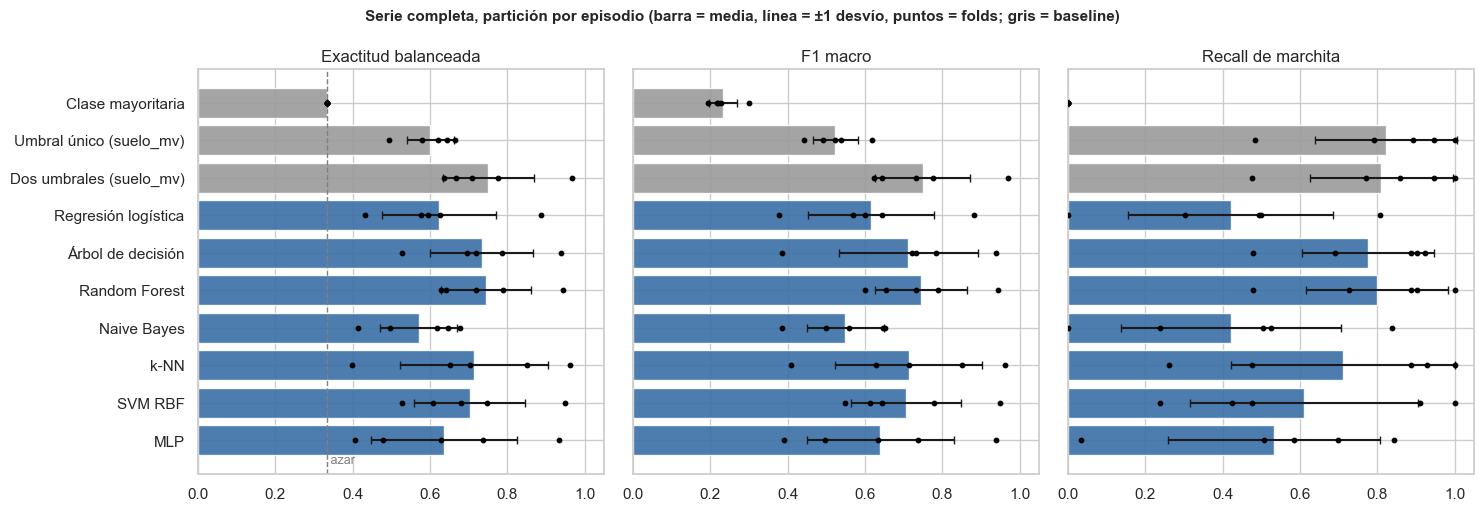

In [10]:
orden = list(MODELOS)
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2), sharey=True)
for ax, m, titulo in zip(axes, ["exactitud_bal", "f1_macro", "recall_marchita"],
                         ["Exactitud balanceada", "F1 macro", "Recall de marchita"]):
    medias = [resultados[n]["folds"][m].mean() for n in orden]
    desv = [resultados[n]["folds"][m].std(ddof=0) for n in orden]
    colores = ["#9a9a9a" if ES_BASELINE[n] else "#3a6ea5" for n in orden]
    ax.barh(orden, medias, xerr=desv, color=colores, capsize=3, alpha=0.9)
    for i, n in enumerate(orden):
        pts = resultados[n]["folds"][m]
        ax.scatter(pts, np.full(len(pts), i), s=10, color="black", zorder=3)
    if m == "exactitud_bal":
        ax.axvline(1 / 3, ls="--", color="gray", lw=1)
        ax.text(1 / 3, len(orden) - 0.4, " azar", color="gray", fontsize=9)
    ax.set_xlim(0, 1.05)
    ax.set_title(titulo)
axes[0].invert_yaxis()
fig.suptitle("Serie completa, partición por episodio (barra = media, línea = ±1 desvío, puntos = folds; "
             "gris = baseline)", fontweight="bold", fontsize=11)
fig.tight_layout()
guardar(fig, "comparacion_modelos.png")
plt.show()

figura: docs/entrega2/fig/matrices_confusion_candidatos.png


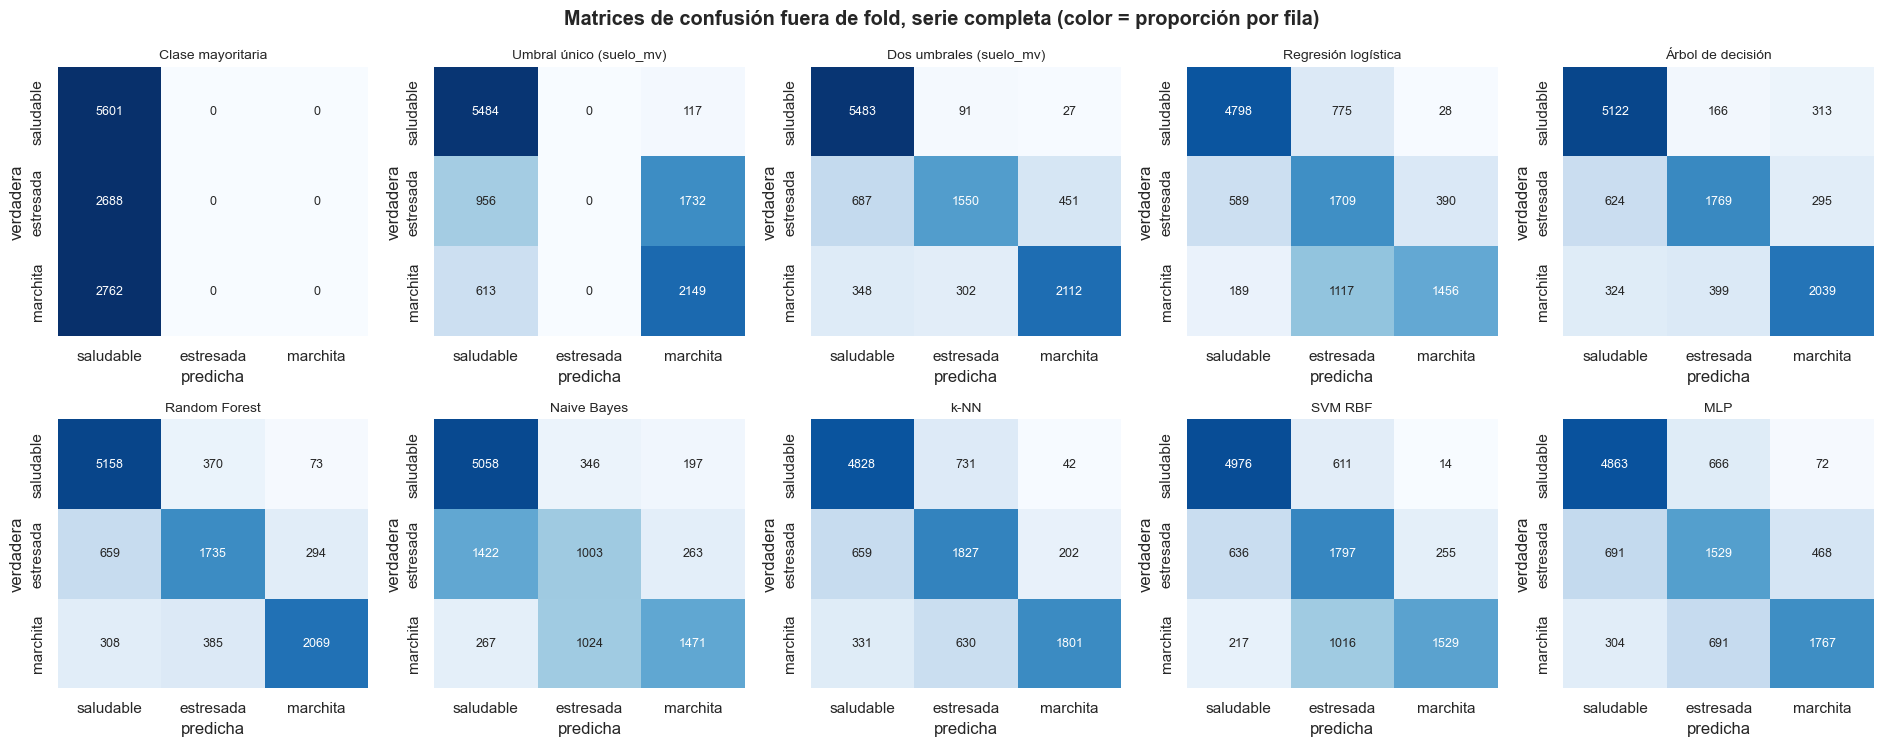

In [11]:
fig, axes = plt.subplots(2, 5, figsize=(19, 7.6))
for ax, n in zip(axes.flat, orden):
    cm = confusion_matrix(y, resultados[n]["oof"], labels=CODIGOS)
    sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=cm, fmt="d", cmap="Blues", vmin=0, vmax=1,
                xticklabels=CLASES, yticklabels=CLASES, cbar=False, ax=ax, annot_kws={"size": 9})
    ax.set_title(n, fontsize=10)
    ax.set_xlabel("predicha")
    ax.set_ylabel("verdadera")
fig.suptitle("Matrices de confusión fuera de fold, serie completa (color = proporción por fila)",
             fontweight="bold")
fig.tight_layout()
guardar(fig, "matrices_confusion_candidatos.png")
plt.show()

**Lectura de §4.**

- **Las búsquedas eligen casi siempre `suelo` o `suelo+delta`.** La información está en la sonda.
- **El desvío entre folds es grande** (0,1–0,19 de F1). Con ~9 episodios de test por fold, la diferencia entre los mejores candidatos está dentro del ruido.
- **El baseline de dos umbrales tiene el mejor F1 macro de la tabla** (0,749 ± 0,123). El Random Forest (0,744 ± 0,119), k-NN, el árbol y SVM quedan a la par.
- **Más abajo:** la regresión logística, el MLP, Naive Bayes, el tocón de un solo umbral (que no puede predecir tres clases) y la clase mayoritaria.

## 5. Costo en la ESP32, métricas sobre lo real y selección

### 5.1 Costo

Para el costo se reentrena cada candidato con la misma búsqueda (partición interna por episodio) sobre **toda** la serie: ese es el modelo que se exportaría. La estimación sale de `costo_esp32` (`modelos.py`): parámetros en `float` de 4 B en flash, RAM de trabajo durante la inferencia, operaciones por predicción y µs a 240 MHz (≈ 10 ciclos por operación y ≈ 1 µs por `expf`). Es un orden de magnitud para comparar; el tiempo del modelo elegido se mide en la placa (`t_us` del log `[INF]`). Todos se exportarían como tablas `static const` en flash: ninguno necesita memoria dinámica.

In [12]:
finales, costos, elegidos_full = {}, {}, {}
for nombre, (est, grilla) in MODELOS.items():
    if grilla:
        b = busqueda(est, grilla).fit(X, y, groups=g)
        finales[nombre] = b.best_estimator_
        elegidos_full[nombre] = b.best_params_
    else:
        finales[nombre] = clone(est).fit(X, y)
    costos[nombre] = costo_esp32(finales[nombre])

costo = pd.DataFrame(costos).T
costo["config"] = [describir(elegidos_full[n]) if n in elegidos_full else
                   f"[{NOMBRE_SUBCONJUNTO.get(tuple(finales[n].named_steps['sel'].columnas), 'todas')}]"
                   for n in costo.index]
costo["flash_KB"] = costo.flash_B.astype(float) / 1024
display(costo[["config", "flash_B", "flash_KB", "ram_B", "ops", "exps", "t_us_est", "exportable"]])

,config,flash_B,flash_KB,ram_B,ops,exps,t_us_est,exportable
Clase mayoritaria,[todas],4,0.004,0,0,0,0.000,sí (constante)
Umbral único (suelo_mv),[suelo],51,0.050,16,2,0,0.083,sí (if/else o tablas)
Dos umbrales (suelo_mv),[suelo],8,0.008,0,2,0,0.083,sí (dos if)
Regresión logística,[suelo+delta] C=0.01,52,0.051,20,25,3,4.042,sí (producto matriz-vector)
Árbol de decisión,"[suelo] max_depth=4, min_samples_leaf=20",441,0.431,16,8,0,0.333,sí (if/else o tablas)
Random Forest,"[suelo] max_depth=5, min_samples_leaf=20",24600,24.023,28,390,0,16.250,sí (tablas)
Naive Bayes,[suelo],36,0.035,12,15,3,3.625,sí (fórmula cerrada)
k-NN,[suelo+delta] n_neighbors=25,99475,97.144,216,88412,0,"3,683.833","sí, pero guarda todo el train"
SVM RBF,[suelo+delta] C=0.1,103260,100.840,28,64524,6452,"9,140.500","sí, pero guarda los vectores soporte"
MLP,"[suelo+delta] alpha=0.001, hidden_layer_sizes=...",220,0.215,64,106,3,7.417,sí (capas densas)


### 5.2 Métricas sobre los episodios reales

Las métricas de §4 se midieron sobre una serie que en su gran mayoría generó el simulador: dicen cuánto aprende el modelo **la regla del simulador**, no la planta. Antes de elegir se mide sobre lo que midió la placa, de tres maneras:

1. **Reales fuera de fold**: las predicciones de §4 (cada fila predicha por un modelo que no vio su episodio), quedándose sólo con las filas `real`. El train incluye los otros episodios reales y el relleno.
2. **Transferencia simulado → real**: entrenar (con la misma búsqueda por episodio) sólo con los episodios simulados y predecir todas las filas reales. Se excluyen enteros los episodios que tienen alguna fila real: los huecos chicos se rellenaron *dentro* de episodios reales y esas filas llevan la etiqueta observada. Es la prueba limpia de si lo que se aprendió del simulador sirve para la planta.
3. **Sólo reales** (referencia, §6): el mismo protocolo con los episodios reales nada más.

Cada una con y sin los episodios dudosos. Con tan pocos episodios reales las métricas se calculan juntando todas las filas reales (por fold quedarían 2 o 3 episodios); el N efectivo sigue siendo el de episodios.

In [13]:
sin_dud = es_real & ~dudoso
print(f"episodios reales: {df[es_real].episodio_id.nunique()} · sin dudosos: {df[sin_dud].episodio_id.nunique()} "
      f"(dudosos: {sorted(EPISODIOS_DUDOSOS)})")
control = {}
for n in orden:
    r = resultados[n]
    for etiqueta, m in [("reales fuera de fold", es_real), ("reales fuera de fold, sin dudosos", sin_dud)]:
        p = r["oof_p"][m] if np.isfinite(r["oof_p"][m]).all() else None
        control[(n, etiqueta)] = metricas(y[m], r["oof"][m], p)

ep_con_real = set(df[es_real].episodio_id)
solo_sim = ~df.episodio_id.isin(ep_con_real).to_numpy()
print(f"train de la transferencia: {solo_sim.sum():,} filas simuladas, {df[solo_sim].episodio_id.nunique()} episodios")
pred_sim2real = {}
for n, (est, grilla) in MODELOS.items():
    if grilla:
        mdl = busqueda(est, grilla).fit(X[solo_sim], y[solo_sim], groups=g[solo_sim]).best_estimator_
    else:
        mdl = clone(est).fit(X[solo_sim], y[solo_sim])
    pred_sim2real[n] = mdl.predict(X)
    pp = proba_3(mdl, X)
    for etiqueta, m in [("sim → real", es_real), ("sim → real, sin dudosos", sin_dud)]:
        control[(n, etiqueta)] = metricas(y[m], pred_sim2real[n][m], None if pp is None else pp[m])

tabla_control = pd.DataFrame(control).T
tabla_control.index.names = ["modelo", "evaluación"]
EVALS_SEL = ["reales fuera de fold", "reales fuera de fold, sin dudosos", "sim → real", "sim → real, sin dudosos"]
for m in ["exactitud_bal", "f1_macro", "recall_marchita"]:
    t = tabla_control[m].unstack("evaluación").reindex(index=orden, columns=EVALS_SEL)
    t.insert(0, "serie completa (CV, media)", resumen_cv[f"{m} (media)"])
    print(f"\n{m}")
    display(t)

episodios reales: 11 · sin dudosos: 7 (dudosos: [8, 9, 11, 14])
train de la transferencia: 9,228 filas simuladas, 36 episodios



exactitud_bal


evaluación,"serie completa (CV, media)",reales fuera de fold,"reales fuera de fold, sin dudosos",sim → real,"sim → real, sin dudosos"
modelo,,,,,
Clase mayoritaria,0.333,0.333,0.333,0.333,0.333
Umbral único (suelo_mv),0.601,0.534,0.664,0.442,0.664
Dos umbrales (suelo_mv),0.751,0.536,0.666,0.536,0.666
Regresión logística,0.623,0.443,0.562,0.418,0.540
Árbol de decisión,0.733,0.412,0.554,0.532,0.654
Random Forest,0.744,0.494,0.644,0.531,0.657
Naive Bayes,0.570,0.535,0.738,0.477,0.613
k-NN,0.712,0.552,0.783,0.564,0.721
SVM RBF,0.702,0.641,0.922,0.555,0.724



f1_macro


evaluación,"serie completa (CV, media)",reales fuera de fold,"reales fuera de fold, sin dudosos",sim → real,"sim → real, sin dudosos"
modelo,,,,,
Clase mayoritaria,0.232,0.162,0.213,0.162,0.213
Umbral único (suelo_mv),0.523,0.388,0.550,0.351,0.557
Dos umbrales (suelo_mv),0.749,0.389,0.551,0.389,0.551
Regresión logística,0.615,0.367,0.551,0.362,0.536
Árbol de decisión,0.712,0.332,0.494,0.386,0.542
Random Forest,0.744,0.402,0.591,0.424,0.588
Naive Bayes,0.549,0.486,0.738,0.396,0.599
k-NN,0.713,0.501,0.759,0.452,0.661
SVM RBF,0.706,0.601,0.918,0.445,0.672



recall_marchita


evaluación,"serie completa (CV, media)",reales fuera de fold,"reales fuera de fold, sin dudosos",sim → real,"sim → real, sin dudosos"
modelo,,,,,
Clase mayoritaria,0.000,0.000,0.000,0.000,0.000
Umbral único (suelo_mv),0.823,0.674,1.000,0.000,0.000
Dos umbrales (suelo_mv),0.811,0.674,1.000,0.674,1.000
Regresión logística,0.421,0.422,0.604,0.422,0.604
Árbol de decisión,0.776,0.665,0.968,0.696,1.000
Random Forest,0.799,0.696,1.000,0.643,0.931
Naive Bayes,0.422,0.432,0.604,0.407,0.604
k-NN,0.711,0.677,1.000,0.677,1.000
SVM RBF,0.610,0.693,1.000,0.661,0.982


### 5.3 Criterio de selección

El contrato (§5.3) pide el mejor F1 macro dentro de 1 desvío del mejor, con flash < 32 KB, sin memoria dinámica y < 1 ms, desempatando por interpretabilidad. Como el F1 de la serie completa mide sobre todo al simulador, se agrega un paso que pesa lo real. Las reglas se fijan antes de mirar quién gana:

1. **Restricciones duras**: flash < 32 KB, < 1 ms estimado, sin memoria dinámica.
2. **Serie completa**: F1 macro (CV por episodio) dentro de 1 desvío del mejor candidato.
3. **Real**: *puntaje real* = media del F1 macro en "reales fuera de fold, sin dudosos" y en "sim → real, sin dudosos". Pasan los que quedan dentro de 1 desvío del mejor puntaje real. El desvío sale de un *bootstrap por episodio*: se remuestrean los episodios reales no dudosos (estratificado por clase, 500 veces) y se recalcula el puntaje del mejor.
4. **Desempate**: interpretabilidad (árbol / umbral = 1 … caja negra = 5), después puntaje real.

Los baselines no son elegibles, pero se reporta si el elegido les gana.

In [14]:
LIMITE_FLASH_B, LIMITE_US = 32 * 1024, 1000
N_BOOT = 500
# Interpretabilidad para el desempate (1 = se lee entero en una hoja; 5 = caja negra).
INTERPRETABILIDAD = {"Clase mayoritaria": 1, "Umbral único (suelo_mv)": 1, "Dos umbrales (suelo_mv)": 1,
                     "Árbol de decisión": 1, "Regresión logística": 2, "Naive Bayes": 2,
                     "Random Forest": 3, "k-NN": 4, "SVM RBF": 5, "MLP": 5}


def f1m(y_, p_):
    return f1_score(y_, p_, labels=CODIGOS, average="macro", zero_division=0)


def puntaje_real(n, filas=None):
    m = sin_dud if filas is None else filas
    return 0.5 * (f1m(y[m], resultados[n]["oof"][m]) + f1m(y[m], pred_sim2real[n][m]))


# Bootstrap por episodio (estratificado por clase) sobre los episodios reales no dudosos.
ep_ok = df[sin_dud].groupby("episodio_id").clase.first()
filas_ep = {e: np.flatnonzero(sin_dud & (g == e)) for e in ep_ok.index}
rng = np.random.default_rng(0)
remuestras = []
for _ in range(N_BOOT):
    eps = np.concatenate([rng.choice(ep_ok[ep_ok == c].index, size=(ep_ok == c).sum(), replace=True)
                          for c in CLASES if (ep_ok == c).any()])
    remuestras.append(np.concatenate([filas_ep[e] for e in eps]))


def puntaje_boot(n):
    v = []
    for idx in remuestras:
        v.append(0.5 * (f1m(y[idx], resultados[n]["oof"][idx]) + f1m(y[idx], pred_sim2real[n][idx])))
    return np.array(v)


sel = pd.DataFrame({
    "f1_macro": resumen_cv["f1_macro (media)"],
    "f1_desvío": resumen_cv["f1_macro (desvío)"],
    "exactitud_bal": resumen_cv["exactitud_bal (media)"],
    "recall_marchita": resumen_cv["recall_marchita (media)"],
    "f1_reales_oof_sd": [f1m(y[sin_dud], resultados[n]["oof"][sin_dud]) for n in orden],
    "f1_sim2real_sd": [f1m(y[sin_dud], pred_sim2real[n][sin_dud]) for n in orden],
    "puntaje_real": [puntaje_real(n) for n in orden],
    "flash_B": costo.flash_B.astype(int), "ram_B": costo.ram_B.astype(int),
    "t_us_est": costo.t_us_est.astype(float),
    "interpretabilidad": pd.Series(INTERPRETABILIDAD),
}, index=orden)
sel["baseline"] = pd.Series(ES_BASELINE)
sel["restricciones_ok"] = (sel.flash_B < LIMITE_FLASH_B) & (sel.t_us_est < LIMITE_US)   # todas sin malloc
cand = sel[~sel.baseline]
mejor_cv = cand.f1_macro.idxmax()
piso_cv = cand.loc[mejor_cv, "f1_macro"] - cand.loc[mejor_cv, "f1_desvío"]
sel["cv_ok"] = sel.f1_macro >= piso_cv
pasan = sel[~sel.baseline & sel.restricciones_ok & sel.cv_ok]
mejor_real = pasan.puntaje_real.idxmax()
boot = puntaje_boot(mejor_real)
desvio_real = boot.std(ddof=0)
piso_real = pasan.loc[mejor_real, "puntaje_real"] - desvio_real
sel["real_ok"] = sel.puntaje_real >= piso_real
sel["cumple"] = ~sel.baseline & sel.restricciones_ok & sel.cv_ok & sel.real_ok

print(f"1) restricciones: fuera por costo → {', '.join(sel[~sel.restricciones_ok].index) or 'ninguno'}")
print(f"2) serie completa: mejor F1 = {mejor_cv} {cand.loc[mejor_cv, 'f1_macro']:.3f} ± "
      f"{cand.loc[mejor_cv, 'f1_desvío']:.3f} → piso {piso_cv:.3f}; pasan: {', '.join(pasan.index)}")
print(f"3) real: mejor puntaje = {mejor_real} {pasan.loc[mejor_real, 'puntaje_real']:.3f}, desvío bootstrap "
      f"por episodio {desvio_real:.3f} ({len(ep_ok)} episodios, {N_BOOT} remuestras) → piso {piso_real:.3f}")
aptos = sel[sel.cumple].sort_values(["interpretabilidad", "puntaje_real"], ascending=[True, False])
print(f"   cumplen todo: {', '.join(aptos.index)}")
elegido = aptos.index[0]
print(f"4) ELEGIDO (interpretabilidad, después puntaje real): {elegido}")
display(sel.drop(columns=["ram_B"]).sort_values("puntaje_real", ascending=False))

1) restricciones: fuera por costo → k-NN, SVM RBF
2) serie completa: mejor F1 = Random Forest 0.744 ± 0.119 → piso 0.625; pasan: Árbol de decisión, Random Forest, MLP
3) real: mejor puntaje = Random Forest 0.589, desvío bootstrap por episodio 0.051 (7 episodios, 500 remuestras) → piso 0.539
   cumplen todo: Random Forest
4) ELEGIDO (interpretabilidad, después puntaje real): Random Forest


,f1_macro,f1_desvío,exactitud_bal,recall_marchita,f1_reales_oof_sd,f1_sim2real_sd,puntaje_real,flash_B,t_us_est,interpretabilidad,baseline,restricciones_ok,cv_ok,real_ok,cumple
SVM RBF,0.706,0.143,0.702,0.610,0.918,0.672,0.795,103260,"9,140.500",5,False,False,True,True,False
k-NN,0.713,0.190,0.712,0.711,0.759,0.661,0.710,99475,"3,683.833",4,False,False,True,True,False
Naive Bayes,0.549,0.100,0.570,0.422,0.738,0.599,0.669,36,3.625,2,False,True,False,True,False
Random Forest,0.744,0.119,0.744,0.799,0.591,0.588,0.589,24600,16.250,3,False,True,True,True,True
Umbral único (suelo_mv),0.523,0.058,0.601,0.823,0.550,0.557,0.553,51,0.083,1,True,True,False,True,False
Dos umbrales (suelo_mv),0.749,0.123,0.751,0.811,0.551,0.551,0.551,8,0.083,1,True,True,True,True,False
Regresión logística,0.615,0.162,0.623,0.421,0.551,0.536,0.544,52,4.042,2,False,True,False,True,False
MLP,0.639,0.190,0.637,0.534,0.526,0.529,0.527,220,7.417,5,False,True,True,False,False
Árbol de decisión,0.712,0.180,0.733,0.776,0.494,0.542,0.518,441,0.333,1,False,True,True,False,False
Clase mayoritaria,0.232,0.036,0.333,0.000,0.213,0.213,0.213,4,0.000,1,True,True,False,False,False


figura: docs/entrega2/fig/rendimiento_vs_costo.png


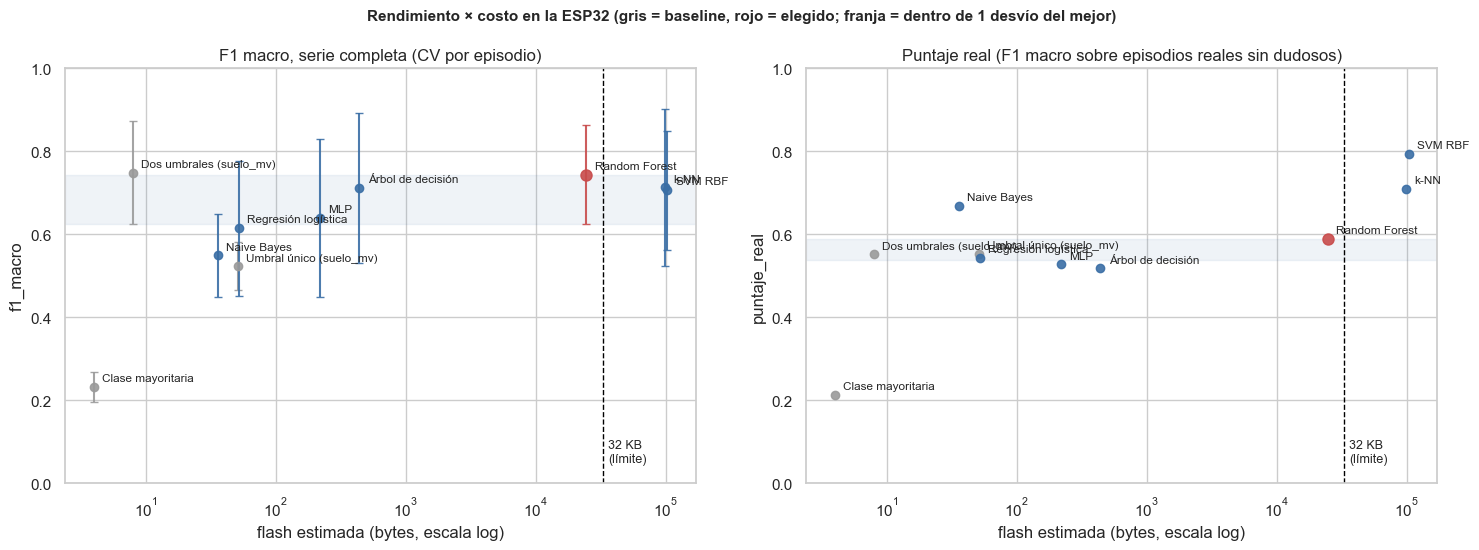

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6), sharey=False)
for ax, (col, titulo) in zip(axes, [("f1_macro", "F1 macro, serie completa (CV por episodio)"),
                                    ("puntaje_real", "Puntaje real (F1 macro sobre episodios reales sin dudosos)")]):
    for n, r in sel.iterrows():
        color = "#9a9a9a" if r.baseline else ("#c84b4b" if n == elegido else "#3a6ea5")
        yerr = r["f1_desvío"] if col == "f1_macro" else None
        ax.errorbar(max(r.flash_B, 4), r[col], yerr=yerr, fmt="o", color=color,
                    ms=8 if n == elegido else 6, capsize=3, alpha=0.9)
        ax.annotate(n, (max(r.flash_B, 4), r[col]), textcoords="offset points", xytext=(6, 4), fontsize=8.5)
    ax.axvline(LIMITE_FLASH_B, color="black", ls="--", lw=1)
    ax.text(LIMITE_FLASH_B * 1.1, 0.05, "32 KB\n(límite)", fontsize=9)
    piso = piso_cv if col == "f1_macro" else piso_real
    techo = cand.loc[mejor_cv, "f1_macro"] if col == "f1_macro" else pasan.loc[mejor_real, "puntaje_real"]
    ax.axhspan(piso, techo, color="#3a6ea5", alpha=0.08)
    ax.set_xscale("log")
    ax.set(xlabel="flash estimada (bytes, escala log)", ylabel=col, ylim=(0, 1), title=titulo)
fig.suptitle("Rendimiento × costo en la ESP32 (gris = baseline, rojo = elegido; franja = dentro de 1 desvío del mejor)",
             fontweight="bold", fontsize=11)
fig.tight_layout()
guardar(fig, "rendimiento_vs_costo.png")
plt.show()

### 5.4 El elegido contra el baseline de umbral

Comparación explícita con las reglas de umbral sobre `suelo_mv`, en la serie completa (fold por fold: los modelos ven exactamente los mismos episodios de test) y sobre lo real.

In [16]:
RIVALES = [elegido, "Dos umbrales (suelo_mv)", "Umbral único (suelo_mv)", "Clase mayoritaria"]
comp = sel.loc[RIVALES, ["f1_macro", "exactitud_bal", "recall_marchita", "f1_reales_oof_sd", "f1_sim2real_sd",
                         "puntaje_real", "flash_B"]]
display(comp)
for rival in RIVALES[1:3]:
    dif = resultados[elegido]["folds"].f1_macro - resultados[rival]["folds"].f1_macro
    print(f"F1 macro por fold, {elegido} − {rival}: {np.round(dif.values, 3)} "
          f"(media {dif.mean():+.3f}; gana en {(dif > 0).sum()} de {len(dif)})")
    d_real = sel.loc[elegido, "puntaje_real"] - sel.loc[rival, "puntaje_real"]
    b_r = puntaje_boot(elegido) - puntaje_boot(rival)
    print(f"   puntaje real: {d_real:+.3f}; en el bootstrap por episodio el elegido gana en "
          f"{(b_r > 0).mean():.0%} de las remuestras, empata en {(b_r == 0).mean():.0%}")

,f1_macro,exactitud_bal,recall_marchita,f1_reales_oof_sd,f1_sim2real_sd,puntaje_real,flash_B
Random Forest,0.744,0.744,0.799,0.591,0.588,0.589,24600
Dos umbrales (suelo_mv),0.749,0.751,0.811,0.551,0.551,0.551,8
Umbral único (suelo_mv),0.523,0.601,0.823,0.550,0.557,0.553,51
Clase mayoritaria,0.232,0.333,0.000,0.213,0.213,0.213,4


F1 macro por fold, Random Forest − Dos umbrales (suelo_mv): [-0.025  0.088 -0.077 -0.023  0.013] (media -0.005; gana en 2 de 5)


   puntaje real: +0.038; en el bootstrap por episodio el elegido gana en 78% de las remuestras, empata en 0%
F1 macro por fold, Random Forest − Umbral único (suelo_mv): [ 0.406  0.29   0.163 -0.018  0.264] (media +0.221; gana en 4 de 5)


   puntaje real: +0.036; en el bootstrap por episodio el elegido gana en 76% de las remuestras, empata en 0%


### 5.5 Configuración final y export

Dentro del tipo elegido se aplica la misma regla de parsimonia: entre las configuraciones de la búsqueda sobre toda la serie con F1 macro interno dentro de 1 desvío de la mejor, la más simple (menos features, después menos profundidad). Tiene que coincidir con `CONFIG_FINAL` de `modelos.py`, que es lo que reentrena el exportador (`python -m plantaia_ml.exportar_c`), y su versión con la de `modelo_plantaia.h`. Si no coincide, la celda lo dice y hay que actualizar `CONFIG_FINAL`, re-exportar y volver a correr el notebook.

In [17]:
b_final = busqueda(*MODELOS[elegido]).fit(X, y, groups=g)
rk = pd.DataFrame(b_final.cv_results_)
rk["config"] = [describir(p) for p in rk.params]
rk["n_features"] = [len(p["sel__columnas"]) for p in rk.params]
rk["profundidad"] = [p.get("clf__max_depth", 0) for p in rk.params]
mejor_h = rk.loc[rk.mean_test_score.idxmax()]
piso_h = mejor_h.mean_test_score - mejor_h.std_test_score
rk["dentro_1_desvío"] = rk.mean_test_score >= piso_h
display(rk.sort_values("mean_test_score", ascending=False)
        [["config", "mean_test_score", "std_test_score", "n_features", "profundidad", "dentro_1_desvío"]]
        .head(10).reset_index(drop=True))
simple = (rk[rk.dentro_1_desvío]
          .sort_values(["n_features", "profundidad", "rank_test_score"], kind="stable").iloc[0])
print(f"mejor configuración interna: {mejor_h.config} = {mejor_h.mean_test_score:.4f} ± {mejor_h.std_test_score:.4f}")
print(f"la más simple dentro de 1 desvío: {simple.config} = {simple.mean_test_score:.4f}")
print("CONFIG_FINAL en modelos.py:       ", CONFIG_FINAL["tipo"], describir(CONFIG_FINAL["params"]))
coincide = CONFIG_FINAL["tipo"] == elegido and all(simple.params.get(k) == v
                                                   for k, v in CONFIG_FINAL["params"].items())
print("→ coincide con CONFIG_FINAL" if coincide else
      "→ ¡NO COINCIDE! Actualizar CONFIG_FINAL en modelos.py, re-exportar y re-ejecutar.")

modelo = modelo_final().fit(X, y)
version = version_modelo(modelo)
en_header = next(l.split('"')[1] for l in RUTA_MODELO.read_text().splitlines()
                 if "PLANTAIA_MODELO_VERSION" in l and "#define" in l)
print(f"versión del modelo (CONFIG_FINAL reentrenado ahora): {version} · en modelo_plantaia.h: {en_header}")
print("→ el header está al día" if version == en_header else
      "→ ¡HEADER DESACTUALIZADO! correr: cd ml && python -m plantaia_ml.exportar_c")

,config,mean_test_score,std_test_score,n_features,profundidad,dentro_1_desvío
0,"[suelo] max_depth=5, min_samples_leaf=20",0.705,0.014,1,5,True
1,"[suelo+delta] max_depth=5, min_samples_leaf=20",0.693,0.070,2,5,True
2,"[suelo] max_depth=5, min_samples_leaf=100",0.653,0.117,1,5,False
3,"[suelo] max_depth=8, min_samples_leaf=100",0.644,0.124,1,8,False
4,"[suelo+delta] max_depth=5, min_samples_leaf=100",0.642,0.017,2,5,False
5,"[suelo+delta] max_depth=8, min_samples_leaf=100",0.641,0.041,2,8,False
6,"[suelo] max_depth=8, min_samples_leaf=20",0.632,0.020,1,8,False
7,"[suelo+delta] max_depth=8, min_samples_leaf=20",0.620,0.018,2,8,False
8,"[suelo+delta] max_depth=3, min_samples_leaf=20",0.582,0.050,2,3,False
9,"[suelo+delta] max_depth=3, min_samples_leaf=100",0.581,0.050,2,3,False


mejor configuración interna: [suelo] max_depth=5, min_samples_leaf=20 = 0.7049 ± 0.0145
la más simple dentro de 1 desvío: [suelo] max_depth=5, min_samples_leaf=20 = 0.7049
CONFIG_FINAL en modelos.py:        Random Forest [suelo] max_depth=5, min_samples_leaf=20
→ coincide con CONFIG_FINAL
versión del modelo (CONFIG_FINAL reentrenado ahora): rf-f0-c42286 · en modelo_plantaia.h: rf-f0-c42286
→ el header está al día


**Si la mejor configuración interna no es la elegida**, se compara con la más simple también sobre lo real. Es una confirmación, no el criterio. Hay dos motivos para desconfiar de `suelo_delta_1h` aunque mejore un poco el F1 interno:

- En el relleno, `suelo_delta_1h` negativo con el sustrato bajo es la firma del *lag* de recuperación tras un riego, que es una regla del simulador.
- En la placa real el sustrato también baja rápido por el **transitorio post-arranque** de la sonda, que sigue después de los primeros minutos descartados.

In [18]:
todo_pb = serie_maceta01(filtrado=False)
todo_pb = todo_pb[(todo_pb.fuente == "real") & todo_pb.valido & todo_pb.post_boot]
Xpb = todo_pb[FEATURES].to_numpy(np.float32)
filas_cfg = {}
pares = [("CONFIG_FINAL", CONFIG_FINAL["params"])]
if mejor_h.params != CONFIG_FINAL["params"]:
    pares.append(("mejor interna", dict(mejor_h.params)))
for etiqueta, params in pares:
    est_c = clone(MODELOS[CONFIG_FINAL["tipo"]][0]).set_params(**params)
    r_c = evaluar(est_c, {}, X, y, g)
    completo = clone(est_c).fit(X, y)
    filas_cfg[f"{etiqueta}: {describir(params)}"] = {
        "F1 macro serie (CV)": r_c["folds"].f1_macro.mean(),
        "F1 macro reales fuera de fold, sin dudosos": f1m(y[sin_dud], r_c["oof"][sin_dud]),
        "exactitud bal. reales fuera de fold": balanced_accuracy_score(y[es_real], r_c["oof"][es_real]),
        "% reales predichas marchita": 100 * (completo.predict(X[es_real]) == 3).mean(),
        "% marchita en la ventana post-arranque descartada": 100 * (completo.predict(Xpb) == 3).mean()
        if len(Xpb) else np.nan,
    }
print(f"% real de marchita en las filas reales: {100 * (y[es_real] == 3).mean():.1f} % · "
      f"filas reales en la ventana post-arranque: {len(Xpb)}")
display(pd.DataFrame(filas_cfg).T)

fija = evaluar(modelo_final(), {}, X, y, g)
print("\nConfiguración final fija (sin búsqueda) vs. búsqueda anidada del tipo, serie completa:")
display(tabla_metricas({"config. final fija": fija, f"{CONFIG_FINAL['tipo']} (búsqueda anidada)":
                        resultados[CONFIG_FINAL["tipo"]]}))
print("costo:", costo_esp32(modelo))
print()
# Barrido de suelo_mv con el resto de las features en la mediana y delta = 0: si el modelo usa sólo
# suelo_mv (como el final), esto ES el modelo entero; se lista dónde cambia la clase predicha.
xs = np.arange(900, 3200.25, 0.25)
Xgrid = np.tile(np.median(X, axis=0), (len(xs), 1)).astype(np.float32)
Xgrid[:, 0] = xs
Xgrid[:, 1] = 0.0
pred_grid = modelo.predict(Xgrid)
proba_grid = modelo.predict_proba(Xgrid)
cambios = np.flatnonzero(np.diff(pred_grid)) + 1
umbrales_final = [float(xs[i]) for i in cambios]
tramos = np.split(np.arange(len(xs)), cambios)
print("features que usa:", [FEATURES[c] for c in modelo.named_steps["sel"].columnas])
print("clase predicha por tramo de suelo_mv (mV):")
for t in tramos:
    print(f"  {xs[t[0]]:7.2f} – {xs[t[-1]]:7.2f}  → {CLASES[pred_grid[t[0]] - 1]}")
if hasattr(modelo.named_steps["clf"], "tree_"):
    print(export_text(modelo.named_steps["clf"],
                      feature_names=[FEATURES[c] for c in modelo.named_steps["sel"].columnas], decimals=1))

% real de marchita en las filas reales: 24.4 % · filas reales en la ventana post-arranque: 136


,F1 macro serie (CV),"F1 macro reales fuera de fold, sin dudosos",exactitud bal. reales fuera de fold,% reales predichas marchita,% marchita en la ventana post-arranque descartada
"CONFIG_FINAL: [suelo] max_depth=5, min_samples_leaf=20",0.715,0.591,0.487,22.937,41.912



Configuración final fija (sin búsqueda) vs. búsqueda anidada del tipo, serie completa:


,exactitud_bal,f1_macro,recall_marchita,roc_auc_ovr
config. final fija,0.716 ± 0.114,0.715 ± 0.112,0.793 ± 0.185,0.822 ± 0.089
Random Forest (búsqueda anidada),0.744 ± 0.115,0.744 ± 0.119,0.799 ± 0.182,0.832 ± 0.081


costo: {'flash_B': 24600, 'ram_B': 28, 'ops': 390, 'exps': 0, 't_us_est': 16.25, 'exportable': 'sí (tablas)'}

features que usa: ['suelo_mv']
clase predicha por tramo de suelo_mv (mV):
   900.00 – 1597.75  → saludable
  1598.00 – 1600.75  → marchita
  1601.00 – 1638.75  → saludable
  1639.00 – 1733.75  → estresada
  1734.00 – 1735.25  → marchita
  1735.50 – 1739.75  → estresada
  1740.00 – 1845.25  → marchita
  1845.50 – 2096.50  → estresada
  2096.75 – 3200.00  → marchita


figura: docs/entrega2/fig/modelo_final_suelo_mv.png


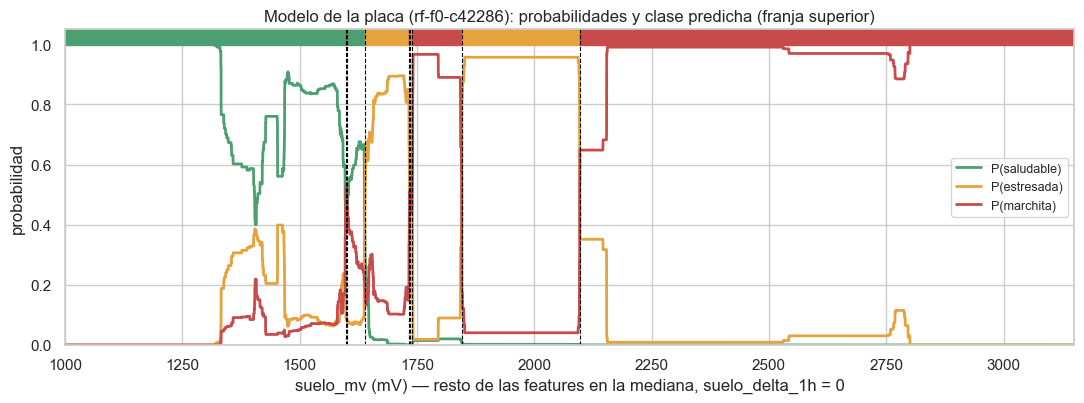

figura: docs/entrega2/fig/matriz_confusion_final.png


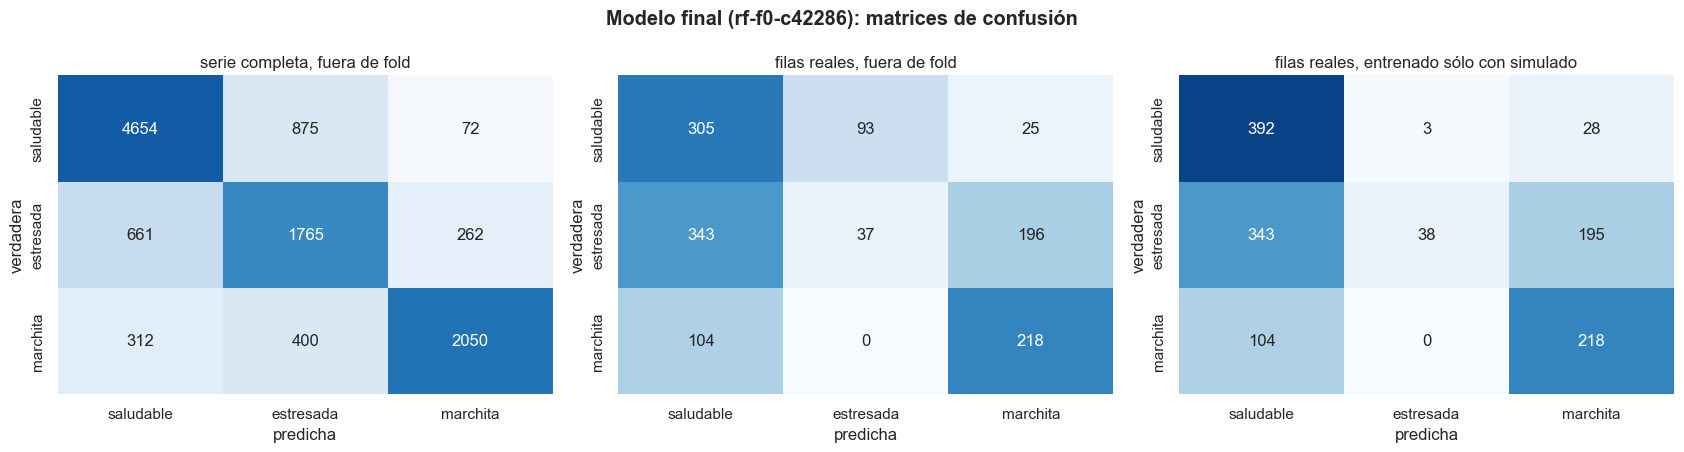

In [19]:
clf_final = modelo.named_steps["clf"]
if hasattr(clf_final, "tree_"):
    fig, ax = plt.subplots(figsize=(11, 5.2))
    plot_tree(clf_final, feature_names=[FEATURES[c] for c in modelo.named_steps["sel"].columnas],
              class_names=CLASES, filled=True, impurity=False, proportion=True, rounded=True,
              precision=2, fontsize=10, ax=ax)
    ax.set_title(f"Modelo de la placa: {version} (proporciones con class_weight='balanced')", fontweight="bold")
    guardar(fig, "arbol_final.png")
    plt.show()
else:
    (FIGURAS / "arbol_final.png").unlink(missing_ok=True)   # de una ejecución anterior con un árbol

# El modelo final como función de suelo_mv: probabilidad de cada clase y clase predicha.
fig, ax = plt.subplots(figsize=(11, 4.2))
for k, c in enumerate(CLASES):
    ax.plot(xs, proba_grid[:, k], color=COLORES[c], lw=2, label=f"P({c})")
for t in tramos:
    ax.axvspan(xs[t[0]], xs[t[-1]], ymin=0.95, ymax=1.0, color=COLORES[CLASES[pred_grid[t[0]] - 1]])
for u in umbrales_final:
    ax.axvline(u, color="black", ls="--", lw=0.8)
ax.set(xlabel="suelo_mv (mV) — resto de las features en la mediana, suelo_delta_1h = 0",
       ylabel="probabilidad", ylim=(0, 1.05), xlim=(1000, 3150),
       title=f"Modelo de la placa ({version}): probabilidades y clase predicha (franja superior)")
ax.legend(loc="center right", fontsize=9)
fig.tight_layout()
guardar(fig, "modelo_final_suelo_mv.png")
plt.show()

oof_fija = fija["oof"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, (titulo, pred, m) in zip(axes, [
        ("serie completa, fuera de fold", oof_fija, np.ones(len(y), bool)),
        ("filas reales, fuera de fold", oof_fija, es_real),
        ("filas reales, entrenado sólo con simulado", None, es_real)]):
    if pred is None:
        est_s = clone(modelo_final()).fit(X[solo_sim], y[solo_sim])
        pred = est_s.predict(X)
    cm = confusion_matrix(y[m], pred[m], labels=CODIGOS)
    sns.heatmap(cm / cm.sum(axis=1, keepdims=True).clip(1), annot=cm, fmt="d", cmap="Blues", vmin=0,
                vmax=1, xticklabels=CLASES, yticklabels=CLASES, cbar=False, ax=ax)
    ax.set(title=titulo, xlabel="predicha", ylabel="verdadera")
fig.suptitle(f"Modelo final ({version}): matrices de confusión", fontweight="bold")
fig.tight_layout()
guardar(fig, "matriz_confusion_final.png")
plt.show()

**Lectura de la selección (criterio de §5.3, fijado antes de ver los resultados y no cambiado).**

1. **Costo.** k-NN y SVM RBF quedan afuera: 97–101 KB y miles de µs estimados, porque guardan el train o los vectores soporte.
2. **Serie completa.** Pasan el Random Forest (mejor F1 entre los candidatos), el árbol y el MLP.
3. **Real.** El puntaje real del mejor (Random Forest, 0,589) tiene un desvío bootstrap por episodio de 0,051. El árbol (0,518) y el MLP (0,527) quedan debajo del piso de 0,539.
4. **Elegido: Random Forest** de 30 árboles, profundidad 5, `min_samples_leaf=20`, **sólo con `suelo_mv`**. Es también la configuración más simple a 1 desvío de la mejor en su búsqueda interna. Estimado: ~24,6 KB de flash (el 75 % del límite de 32 KB), 390 operaciones, ~16 µs; en el replay en host, 1–3 µs.

**Contra el baseline de umbral: el elegido no lo supera de forma clara, y hay que decirlo así.**

- *Serie completa:* empate. F1 macro 0,744 contra 0,749; el RF gana en 2 de 5 folds.
- *Sobre lo real:* el RF tiene un puntaje un poco mayor (0,589 contra 0,551, +0,038; gana en el 78 % de las remuestras del bootstrap). Pero la diferencia es menor que el desvío (0,051), y en **exactitud balanceada sobre lo real los dos umbrales le ganan** (0,536 contra 0,494 con todos los episodios; 0,666 contra 0,644 sin dudosos).
- *Al umbral único* le gana con claridad en la serie completa (+0,221 de F1, 4 de 5 folds), pero sobre lo real sólo por +0,036 de puntaje. *A la clase mayoritaria* le gana en todo.

**Qué es el modelo final.** Como sólo usa `suelo_mv`, es una función escalonada de la sonda (figura `modelo_final_suelo_mv.png`):

| tramo de `suelo_mv` | clase | de dónde sale |
|---|---|---|
| hasta ~1600 mV | `saludable` | |
| ~1640–1735 | `estresada` | curva de octubre |
| ~1740–1845 | `marchita` | curva de octubre (ep. 12) |
| ~1845–2097 | `estresada` | estresadas de septiembre y el ep. 13 |
| desde ~2097 | `marchita` | septiembre |

- Además tiene dos islitas de `marchita` de 1–3 mV en ~1598 y ~1734 mV, artefactos del promedio de 30 árboles.
- La regla **no es monótona**: superpone las dos escalas de la sonda (septiembre y octubre) que la corrosión separó.
- La regla de dos umbrales no puede representar eso, y aun así rinde igual. Eso indica que la ganancia del RF es marginal y depende de pocos episodios.

## 6. Control con datos reales

§5.2 ya dio las métricas sobre lo real que usa la selección. Esta sección agrega la **referencia entrenando sólo con reales** y mira por qué falla lo que falla: episodio por episodio, la frontera sobre `suelo_mv`, la deriva de la sonda y la hora del día.

### 6.1 Referencia: sólo con los episodios reales

Mismo protocolo (partición externa e interna por episodio) usando únicamente las filas reales. Reproduce el hallazgo del notebook 02 con los episodios nuevos.

In [20]:
Xr, yr, gr, dr = X[es_real], y[es_real], g[es_real], dudoso[es_real]
print(f"sólo reales: {len(yr):,} filas, {len(np.unique(gr))} episodios "
      f"({pd.Series(yr).map(dict(zip(CODIGOS, CLASES))).groupby(gr).first().value_counts().to_dict()})")
print("(algunos folds internos quedan con una sola clase: esas configuraciones se descartan con NaN)")
solo_reales = {}
for n, (est, grilla) in MODELOS.items():
    solo_reales[n] = evaluar(est, grilla, Xr, yr, gr, tolerante=True)
    for etiqueta, m in [("sólo reales (CV por episodio)", np.ones(len(yr), bool)),
                        ("sólo reales, sin dudosos", ~dr)]:
        p = solo_reales[n]["oof_p"][m]
        tabla_control.loc[(n, etiqueta), :] = pd.Series(
            metricas(yr[m], solo_reales[n]["oof"][m], p if np.isfinite(p).all() else None))

EVALS = EVALS_SEL + ["sólo reales (CV por episodio)", "sólo reales, sin dudosos"]
for m in ["exactitud_bal", "f1_macro", "recall_marchita"]:
    t = tabla_control[m].unstack("evaluación").reindex(index=orden, columns=EVALS)
    t.insert(0, "serie completa (CV, media)", resumen_cv[f"{m} (media)"])
    print(f"\n{m} — filas reales agrupadas (la primera columna es la de §4, para comparar)")
    display(t)
print("\nROC-AUC OvR sobre filas reales (NaN = sin probabilidades o falta una clase):")
display(tabla_control["roc_auc_ovr"].unstack("evaluación").reindex(index=orden, columns=EVALS))

sólo reales: 1,321 filas, 11 episodios ({'estresada': 5, 'marchita': 3, 'saludable': 3})
(algunos folds internos quedan con una sola clase: esas configuraciones se descartan con NaN)



exactitud_bal — filas reales agrupadas (la primera columna es la de §4, para comparar)


evaluación,"serie completa (CV, media)",reales fuera de fold,"reales fuera de fold, sin dudosos",sim → real,"sim → real, sin dudosos",sólo reales (CV por episodio),"sólo reales, sin dudosos"
modelo,,,,,,,
Clase mayoritaria,0.333,0.333,0.333,0.333,0.333,0.092,0.232
Umbral único (suelo_mv),0.601,0.534,0.664,0.442,0.664,0.144,0.212
Dos umbrales (suelo_mv),0.751,0.536,0.666,0.536,0.666,0.314,0.495
Regresión logística,0.623,0.443,0.562,0.418,0.540,0.412,0.616
Árbol de decisión,0.733,0.412,0.554,0.532,0.654,0.172,0.325
Random Forest,0.744,0.494,0.644,0.531,0.657,0.257,0.402
Naive Bayes,0.570,0.535,0.738,0.477,0.613,0.269,0.402
k-NN,0.712,0.552,0.783,0.564,0.721,0.204,0.370
SVM RBF,0.702,0.641,0.922,0.555,0.724,0.361,0.519



f1_macro — filas reales agrupadas (la primera columna es la de §4, para comparar)


evaluación,"serie completa (CV, media)",reales fuera de fold,"reales fuera de fold, sin dudosos",sim → real,"sim → real, sin dudosos",sólo reales (CV por episodio),"sólo reales, sin dudosos"
modelo,,,,,,,
Clase mayoritaria,0.232,0.162,0.213,0.162,0.213,0.072,0.106
Umbral único (suelo_mv),0.523,0.388,0.550,0.351,0.557,0.130,0.225
Dos umbrales (suelo_mv),0.749,0.389,0.551,0.389,0.551,0.320,0.479
Regresión logística,0.615,0.367,0.551,0.362,0.536,0.390,0.606
Árbol de decisión,0.712,0.332,0.494,0.386,0.542,0.167,0.265
Random Forest,0.744,0.402,0.591,0.424,0.588,0.221,0.338
Naive Bayes,0.549,0.486,0.738,0.396,0.599,0.223,0.365
k-NN,0.713,0.501,0.759,0.452,0.661,0.191,0.305
SVM RBF,0.706,0.601,0.918,0.445,0.672,0.298,0.469



recall_marchita — filas reales agrupadas (la primera columna es la de §4, para comparar)


evaluación,"serie completa (CV, media)",reales fuera de fold,"reales fuera de fold, sin dudosos",sim → real,"sim → real, sin dudosos",sólo reales (CV por episodio),"sólo reales, sin dudosos"
modelo,,,,,,,
Clase mayoritaria,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Umbral único (suelo_mv),0.823,0.674,1.000,0.000,0.000,0.000,0.000
Dos umbrales (suelo_mv),0.811,0.674,1.000,0.674,1.000,0.407,0.604
Regresión logística,0.421,0.422,0.604,0.422,0.604,0.220,0.327
Árbol de decisión,0.776,0.665,0.968,0.696,1.000,0.037,0.055
Random Forest,0.799,0.696,1.000,0.643,0.931,0.000,0.000
Naive Bayes,0.422,0.432,0.604,0.407,0.604,0.000,0.000
k-NN,0.711,0.677,1.000,0.677,1.000,0.034,0.051
SVM RBF,0.610,0.693,1.000,0.661,0.982,0.043,0.065



ROC-AUC OvR sobre filas reales (NaN = sin probabilidades o falta una clase):


evaluación,reales fuera de fold,"reales fuera de fold, sin dudosos",sim → real,"sim → real, sin dudosos",sólo reales (CV por episodio),"sólo reales, sin dudosos"
modelo,,,,,,
Clase mayoritaria,0.500,0.500,0.500,0.500,0.302,0.424
Umbral único (suelo_mv),0.504,0.802,0.651,0.877,0.241,0.508
Dos umbrales (suelo_mv),NaN,NaN,NaN,NaN,NaN,NaN
Regresión logística,0.585,0.842,0.627,0.817,0.499,0.794
Árbol de decisión,0.597,0.749,0.652,0.872,0.284,0.530
Random Forest,0.585,0.718,0.654,0.781,0.378,0.562
Naive Bayes,0.571,0.858,0.638,0.855,0.319,0.589
k-NN,0.594,0.858,0.665,0.809,0.337,0.520
SVM RBF,NaN,NaN,NaN,NaN,NaN,NaN


figura: docs/entrega2/fig/control_reales.png


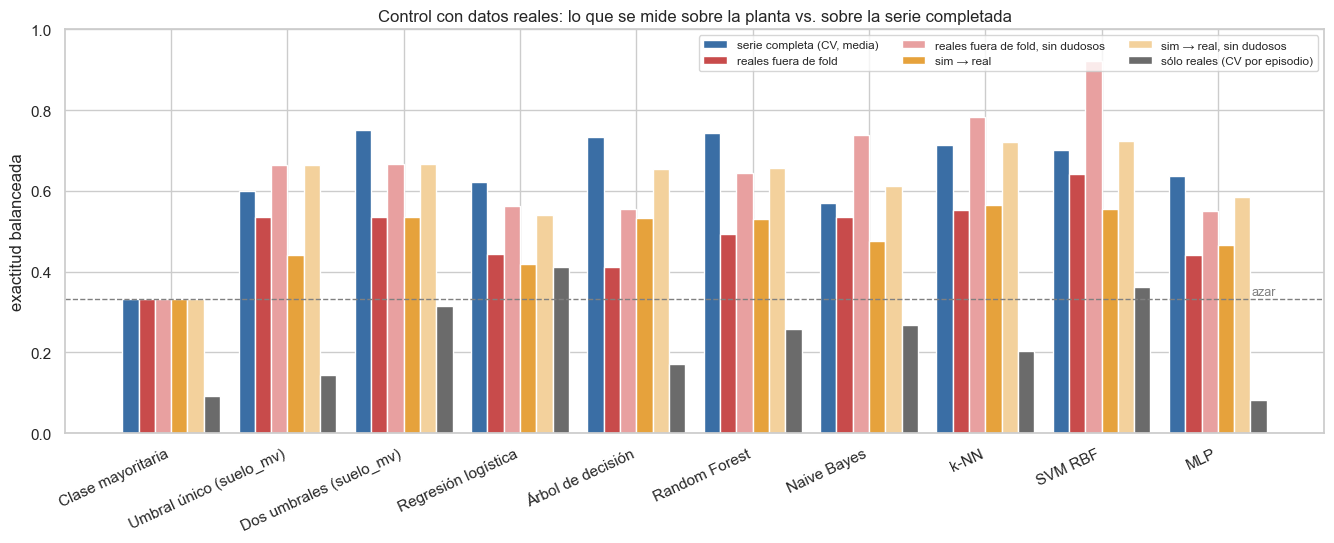

In [21]:
fig, ax = plt.subplots(figsize=(13.5, 5.6))
cols = ["serie completa (CV, media)", "reales fuera de fold", "reales fuera de fold, sin dudosos",
        "sim → real", "sim → real, sin dudosos", "sólo reales (CV por episodio)"]
t = tabla_control["exactitud_bal"].unstack("evaluación").reindex(index=orden)
t.insert(0, "serie completa (CV, media)", resumen_cv["exactitud_bal (media)"])
t = t[cols]
paleta = ["#3a6ea5", "#c84b4b", "#e8a0a0", "#e6a23c", "#f3d19c", "#6b6b6b"]
ancho = 0.14
for i, (c, col) in enumerate(zip(cols, paleta)):
    ax.bar(np.arange(len(orden)) + (i - 2.5) * ancho, t[c], ancho, label=c, color=col)
ax.axhline(1 / 3, ls="--", color="gray", lw=1)
ax.text(len(orden) - 0.5, 1 / 3 + 0.01, "azar", color="gray", fontsize=9, ha="right")
ax.set_xticks(np.arange(len(orden)), orden, rotation=25, ha="right")
ax.set(ylabel="exactitud balanceada", ylim=(0, 1),
       title="Control con datos reales: lo que se mide sobre la planta vs. sobre la serie completada")
ax.legend(fontsize=8.5, ncol=3, loc="upper right")
fig.tight_layout()
guardar(fig, "control_reales.png")
plt.show()

### 6.2 Sensibilidad al episodio 13 (el conflicto del 19/10)

El 19/10 hay dos observaciones con el botón a pocas horas de distancia y con la sonda casi en el mismo valor:

- el **ep. 12**: `marchita`, de noche, con ~1756 mV;
- el **ep. 13**: `estresada`, a la mañana siguiente, con ~1796 mV en la pulsación. La mediana del episodio es más alta porque después de la pulsación siguió 11–12 h propagado mientras el sustrato se secaba, hasta el riego.

Ninguna regla monótona sobre `suelo_mv` respeta las dos. El relleno v2 se calibró **creyéndole al 12** (umbral de marchita de octubre ~1745 mV; ver `data/sintetico/README.md`). Por eso no se marca dudoso al 13: sería circular, porque se descartaría justamente el episodio que contradice la calibración. En cambio se reporta la sensibilidad: las mismas métricas sobre lo real, con todos, sin dudosos, sin el 13 y sin dudosos ni el 13. **El criterio de selección de §5.3 no cambia**: usa "sin dudosos".

In [22]:
es_13 = (g == 13)
mascaras = {"todos": es_real, "sin dudosos": sin_dud, "sin el 13": es_real & ~es_13,
            "sin dudosos ni el 13": sin_dud & ~es_13}
filas_s = {}
for n in orden:
    for nombre_m, m in mascaras.items():
        filas_s[(n, nombre_m)] = {
            "exactitud_bal reales fuera de fold": balanced_accuracy_score(y[m], resultados[n]["oof"][m]),
            "F1 macro reales fuera de fold": f1m(y[m], resultados[n]["oof"][m]),
            "exactitud_bal sim → real": balanced_accuracy_score(y[m], pred_sim2real[n][m]),
            "F1 macro sim → real": f1m(y[m], pred_sim2real[n][m]),
            "recall marchita sim → real": recall_marchita(y[m], pred_sim2real[n][m]),
        }
sensibilidad = pd.DataFrame(filas_s).T
sensibilidad.index.names = ["modelo", "episodios reales"]
for col in ["exactitud_bal reales fuera de fold", "exactitud_bal sim → real", "F1 macro sim → real"]:
    print(f"\n{col}")
    display(sensibilidad[col].unstack("episodios reales").reindex(index=orden, columns=list(mascaras)))


exactitud_bal reales fuera de fold


episodios reales,todos,sin dudosos,sin el 13,sin dudosos ni el 13
modelo,,,,
Clase mayoritaria,0.333,0.333,0.333,0.333
Umbral único (suelo_mv),0.534,0.664,0.534,0.664
Dos umbrales (suelo_mv),0.536,0.666,0.536,0.666
Regresión logística,0.443,0.562,0.417,0.497
Árbol de decisión,0.412,0.554,0.420,0.634
Random Forest,0.494,0.644,0.500,0.724
Naive Bayes,0.535,0.738,0.460,0.561
k-NN,0.552,0.783,0.520,0.792
SVM RBF,0.641,0.922,0.581,0.865



exactitud_bal sim → real


episodios reales,todos,sin dudosos,sin el 13,sin dudosos ni el 13
modelo,,,,
Clase mayoritaria,0.333,0.333,0.333,0.333
Umbral único (suelo_mv),0.442,0.664,0.379,0.664
Dos umbrales (suelo_mv),0.536,0.666,0.536,0.666
Regresión logística,0.418,0.540,0.393,0.484
Árbol de decisión,0.532,0.654,0.532,0.654
Random Forest,0.531,0.657,0.528,0.655
Naive Bayes,0.477,0.613,0.445,0.531
k-NN,0.564,0.721,0.573,0.805
SVM RBF,0.555,0.724,0.563,0.823



F1 macro sim → real


episodios reales,todos,sin dudosos,sin el 13,sin dudosos ni el 13
modelo,,,,
Clase mayoritaria,0.162,0.213,0.175,0.240
Umbral único (suelo_mv),0.351,0.557,0.285,0.484
Dos umbrales (suelo_mv),0.389,0.551,0.427,0.608
Regresión logística,0.362,0.536,0.348,0.506
Árbol de decisión,0.386,0.542,0.422,0.596
Random Forest,0.424,0.588,0.453,0.630
Naive Bayes,0.396,0.599,0.366,0.530
k-NN,0.452,0.661,0.505,0.824
SVM RBF,0.445,0.672,0.501,0.838


### 6.3 El modelo final, episodio por episodio (reales)

Proporción de filas de cada episodio real que el modelo final asigna a cada clase (entrenado con toda la serie, como va a la placa) y el acierto con las tres evaluaciones. Agregados por episodio: no se listan filas.

In [23]:
p_final_todo = modelo.predict(X)
p_final_sim = clone(modelo_final()).fit(X[solo_sim], y[solo_sim]).predict(X)
filas_tab = []
for e, d in df[es_real].groupby("episodio_id"):
    idx = d.index.to_numpy()
    fila = {"episodio": e, "clase": d.clase.iloc[0], "dudoso": bool(d.dudoso.iloc[0]), "filas": len(d),
            "suelo_mv_mediana": d.suelo_mv.median()}
    for c, nombre in zip(CODIGOS, CLASES):
        fila[f"final→{nombre[:5]}"] = (p_final_todo[idx] == c).mean()
    fila["acierto final (train)"] = (p_final_todo[idx] == y[idx]).mean()
    fila["acierto fuera de fold"] = (oof_fija[idx] == y[idx]).mean()
    fila["acierto sim→real"] = (p_final_sim[idx] == y[idx]).mean()
    filas_tab.append(fila)
por_ep = pd.DataFrame(filas_tab).set_index("episodio")
display(por_ep)
ok = por_ep["acierto fuera de fold"] > 0.5
print(f"episodios reales con más de la mitad de las filas bien (fuera de fold): {ok.sum()} de {len(por_ep)}; "
      f"sin dudosos: {ok[~por_ep.dudoso].sum()} de {(~por_ep.dudoso).sum()}")
ok_s = por_ep["acierto sim→real"] > 0.5
print(f"ídem entrenando sólo con simulado: {ok_s.sum()} de {len(por_ep)}; "
      f"sin dudosos: {ok_s[~por_ep.dudoso].sum()} de {(~por_ep.dudoso).sum()}")

,clase,dudoso,filas,suelo_mv_mediana,final→salud,final→estre,final→march,acierto final (train),acierto fuera de fold,acierto sim→real
episodio,,,,,,,,,,
1,marchita,False,131,"2,832.000",0.000,0.000,1.000,1.000,1.000,1.000
3,estresada,False,23,"2,769.500",0.000,0.000,1.000,0.000,0.000,0.000
6,estresada,False,69,"2,050.000",0.000,0.754,0.246,0.754,0.536,0.536
8,marchita,True,105,"1,512.000",0.990,0.000,0.010,0.010,0.010,0.010
9,estresada,True,51,"1,454.000",1.000,0.000,0.000,0.000,0.000,0.000
10,saludable,False,137,"1,504.000",0.971,0.022,0.007,0.971,0.912,0.971
11,saludable,True,27,"1,785.500",0.000,0.074,0.926,0.000,0.000,0.000
12,marchita,False,86,"1,758.000",0.000,0.000,1.000,1.000,1.000,1.000
13,estresada,False,136,"1,929.750",0.000,0.860,0.140,0.860,0.000,0.000


episodios reales con más de la mitad de las filas bien (fuera de fold): 5 de 11; sin dudosos: 5 de 7
ídem entrenando sólo con simulado: 5 de 11; sin dudosos: 5 de 7


### 6.4 La frontera sobre `suelo_mv` y la deriva de la sonda

Distribución de `suelo_mv` por clase en el relleno y en lo real, con los cortes del modelo final. El modelo final sólo mira esta variable: lo que se ve acá es exactamente su frontera de decisión.

figura: docs/entrega2/fig/fronteras_suelo_mv.png


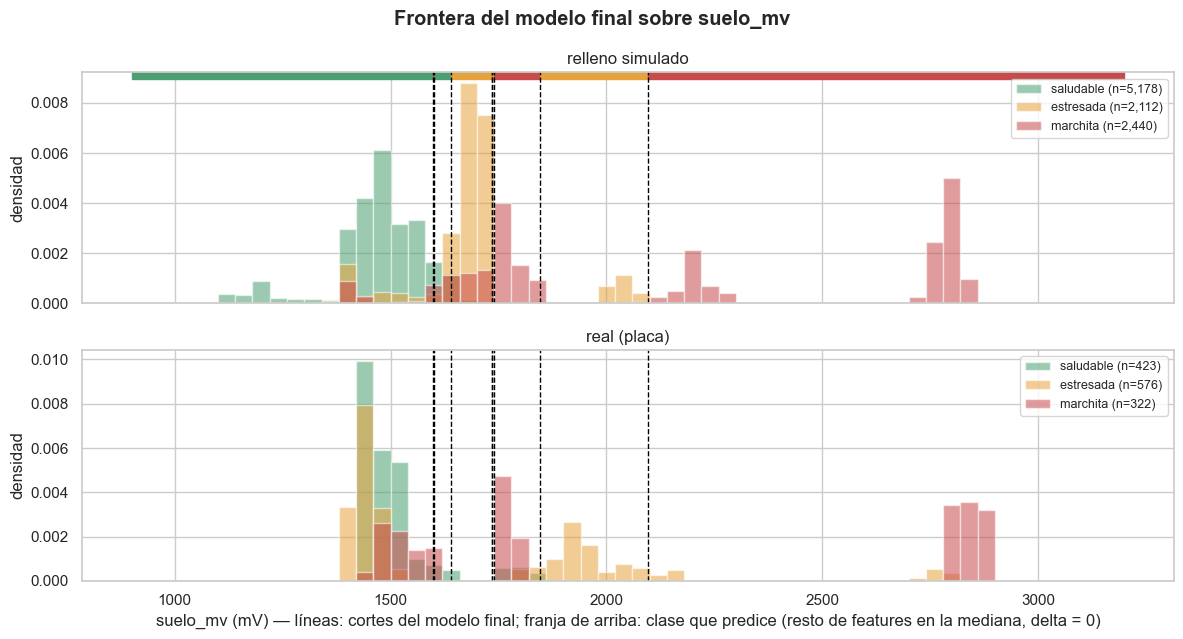

cambios de clase sobre suelo_mv (mV): [1598.0, 1601.0, 1639.0, 1734.0, 1735.5, 1740.0, 1845.5, 2096.75]


In [24]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
bins = np.arange(900, 3200, 40)
for ax, f in zip(axes, ["simulada_relleno", "real"]):
    d = df[df.fuente == f]
    for c in CLASES:
        v = d.loc[d.clase == c, "suelo_mv"]
        if len(v):
            ax.hist(v, bins=bins, density=True, alpha=0.55, color=COLORES[c], label=f"{c} (n={len(v):,})")
    for u in umbrales_final:
        ax.axvline(u, color="black", ls="--", lw=1)
    ax.set_ylabel("densidad")
    ax.set_title(FUENTES[f])
    ax.legend(fontsize=9, loc="upper right")
for t in tramos:
    axes[0].axvspan(xs[t[0]], xs[t[-1]], ymin=0.97, ymax=1.0, color=COLORES[CLASES[pred_grid[t[0]] - 1]])
axes[1].set_xlabel("suelo_mv (mV) — líneas: cortes del modelo final; franja de arriba: clase que predice "
                   "(resto de features en la mediana, delta = 0)")
fig.suptitle("Frontera del modelo final sobre suelo_mv", fontweight="bold")
fig.tight_layout()
guardar(fig, "fronteras_suelo_mv.png")
plt.show()
print("cambios de clase sobre suelo_mv (mV):", [round(u, 2) for u in umbrales_final])

In [25]:
# Deriva de la sonda en lo real: el mismo estado de la planta, otra lectura según el mes.
r = df[es_real].assign(periodo=np.where(df.loc[es_real, "ts"] < "2026-10-01", "septiembre", "octubre"))
display(r.groupby(["clase", "periodo"]).agg(episodios=("episodio_id", "nunique"), filas=("ts", "size"),
                                            suelo_mv_mediana=("suelo_mv", "median"))
        .unstack("periodo").reindex(CLASES))
s = df[~es_real].assign(periodo=np.where(df.loc[~es_real, "ts"] < "2026-10-01", "septiembre", "octubre"))
print("Relleno simulado, mediana de suelo_mv por clase y mes:")
display(s.groupby(["clase", "periodo"]).suelo_mv.median().unstack("periodo").reindex(CLASES))
print(f"máximo de suelo_mv real en octubre (serie filtrada): {r[r.periodo == 'octubre'].suelo_mv.max():.0f} mV · "
      f"filas simuladas de octubre por encima: {(s[s.periodo == 'octubre'].suelo_mv > r[r.periodo == 'octubre'].suelo_mv.max()).mean():.1%}")

episodios              filas            suelo_mv_mediana           
periodo     octubre septiembre octubre septiembre          octubre septiembre
clase                                                                        
saludable     3.000        NaN 423.000        NaN        1,480.000        NaN
estresada     3.000      2.000 484.000     92.000        1,455.250  2,064.000
marchita      2.000      1.000 191.000    131.000        1,592.500  2,832.000

Relleno simulado, mediana de suelo_mv por clase y mes:


periodo,octubre,septiembre
clase,,
saludable,"1,488.500","1,456.000"
estresada,"1,691.000","1,674.000"
marchita,"1,709.250","2,272.000"


máximo de suelo_mv real en octubre (serie filtrada): 1954 mV · filas simuladas de octubre por encima: 0.0%


### 6.5 ¿La clase sigue a la hora del día?

La hora no es feature, pero si la clase está atada al reloj, la luz y la temperatura pueden colarla. Se mide la asociación entre la franja horaria (8 franjas de 3 h, hora local UTC−3) y la clase con la V de Cramér: 0 = independientes, 1 = la franja determina la clase.

V de Cramér franja horaria × clase:
  reales            0.47
  relleno simulado  0.10
  predicción del modelo final sobre los reales: 0.39
Mediana de luz_mv por clase:


fuente,real,simulada_relleno
clase,,
saludable,"1,418.500","1,141.000"
estresada,"1,624.750","1,010.250"
marchita,142.000,"1,197.000"


figura: docs/entrega2/fig/clase_por_hora.png


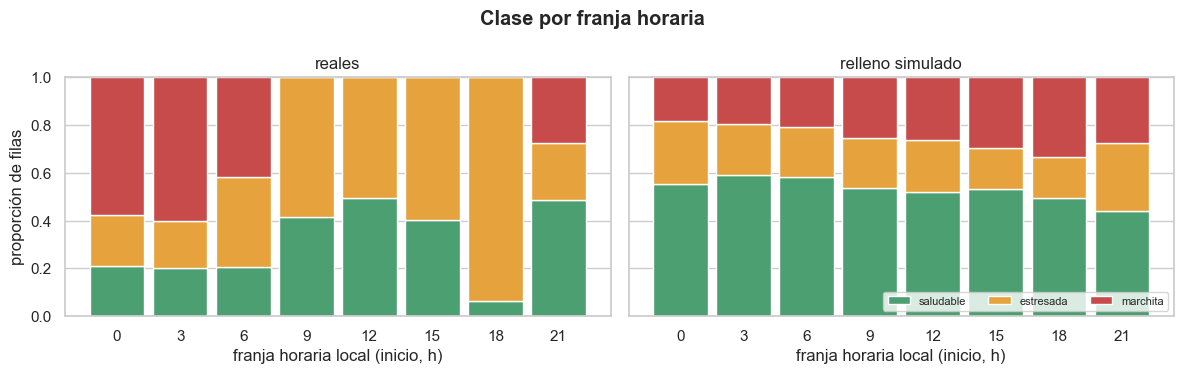

In [26]:
def cramer_v(a, b):
    t = pd.crosstab(a, b)
    chi2 = stats.chi2_contingency(t)[0]
    return np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))


franja = ((df.ts - pd.Timedelta(hours=3)).dt.hour // 3) * 3
print("V de Cramér franja horaria × clase:")
for etiqueta, m in [("reales", es_real), ("relleno simulado", ~es_real)]:
    print(f"  {etiqueta:<17} {cramer_v(franja[m], df.clase[m]):.2f}")
print(f"  predicción del modelo final sobre los reales: {cramer_v(franja[es_real], pd.Series(p_final_todo[es_real], index=franja[es_real].index)):.2f}")
print("Mediana de luz_mv por clase:")
display(df.groupby(["clase", "fuente"]).luz_mv.median().unstack("fuente").reindex(CLASES))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (etiqueta, m) in zip(axes, [("reales", es_real), ("relleno simulado", ~es_real)]):
    p = pd.crosstab(franja[m], df.clase[m], normalize="index").reindex(columns=CLASES).fillna(0)
    base = np.zeros(len(p))
    for c in CLASES:
        ax.bar(p.index, p[c], 2.6, bottom=base, color=COLORES[c], label=c)
        base += p[c].values
    ax.set(title=etiqueta, xlabel="franja horaria local (inicio, h)", xticks=range(0, 24, 3))
axes[0].set_ylabel("proporción de filas")
axes[1].legend(ncol=3, fontsize=8, loc="lower right")
fig.suptitle("Clase por franja horaria", fontweight="bold")
fig.tight_layout()
guardar(fig, "clase_por_hora.png")
plt.show()

**Lectura del control con datos reales.**

- **El número de la serie completa promete más de lo que se ve en lo real.**
  - Fuera de fold, el RF da 0,494 de exactitud balanceada con todos los episodios reales y 0,644 sin dudosos.
  - La transferencia simulado → real da 0,531 y 0,657. Lo que el simulador v2 enseña sirve para septiembre (ep. 1) y para la marchita de octubre (ep. 12, 100 %), pero no para la estresada real (ep. 3, 6, 13).
- **Entrenando sólo con reales, nada generaliza.** El RF da 0,257 / 0,402, y el mejor es la regresión logística con 0,412 / 0,616. Es el hallazgo del notebook 02.
- **SVM y k-NN** dan los mejores números sobre lo real fuera de fold (SVM 0,922 sin dudosos), pero quedaron afuera por costo (~100 KB) y con 7 episodios la diferencia no es concluyente.

**El conflicto del 19/10 (ep. 12 vs. ep. 13).**

- Las dos pulsaciones están a 40 mV: la marchita del 12, de noche, con 1756 mV, y la estresada del 13, a la mañana, con 1796 mV.
- El relleno v2 se calibró creyéndole al 12, así que todo modelo entrenado con él predice el 13 como `marchita`: 0 % fuera de fold y en sim → real. Sólo lo acierta cuando el propio 13 está en el train (el modelo final, 86 %).
- Marcar dudoso al 13 sería circular: descartaría justo el episodio que contradice la calibración. Se reporta la sensibilidad: sin el 13 (y sin dudosos), la exactitud balanceada fuera de fold del RF sube de 0,644 a 0,724; la de sim → real queda igual (0,657 → 0,655).
- **Sólo las fotos de la ESP32-CAM del 19/10 pueden resolverlo.**

**Por episodio**, el RF falla en:

- las etiquetas dudosas (8, 9, 11, 14), donde la clase no se condice con el sustrato;
- el ep. 3 (estresada sobre el radiador, con el sustrato de una marchita);
- el ep. 13.

**La hora.** La clase real está fuertemente atada a la franja horaria (V de Cramér 0,47; marchita sólo de noche); la del relleno v2 casi nada (0,10). El modelo no usa ni la luz ni la hora: la asociación de su predicción con la franja (0,39) llega sólo a través del sustrato.

### 6.6 Análisis secundario: binario *requiere cuidado*

`estresada` ∪ `marchita` contra `saludable`. No es el modelo de la placa (que es de 3 clases): sirve para ver si al menos la pregunta gruesa "¿hay que hacer algo?" se puede contestar. Mismo protocolo por episodio, con los baselines y tres candidatos baratos de exportar (árbol, regresión logística, Naive Bayes), en la serie completa, en las filas reales fuera de fold y en la transferencia simulado → real.

In [27]:
yb = (y >= 2).astype(int)        # 1 = requiere cuidado


def ajustar_bin(est, grilla, idx):
    if grilla:
        return busqueda(est, grilla).fit(X[idx], yb[idx], groups=g[idx]).best_estimator_
    return clone(est).fit(X[idx], yb[idx])


def evaluar_binario(est, grilla):
    folds = []
    oof = np.zeros(len(yb), int)
    for tr, te in particion_externa().split(X, y, g):   # mismos folds que §4 (estratificados en 3 clases)
        mdl = ajustar_bin(est, grilla, tr)
        oof[te] = mdl.predict(X[te])
        pp = mdl.predict_proba(X[te])[:, list(mdl.classes_).index(1)] if hasattr(mdl, "predict_proba") else None
        folds.append({"exactitud_bal": balanced_accuracy_score(yb[te], oof[te]),
                      "f1_cuidado": f1_score(yb[te], oof[te], zero_division=0),
                      "recall_cuidado": recall_score(yb[te], oof[te], zero_division=0),
                      "roc_auc": roc_auc_score(yb[te], pp) if pp is not None else np.nan})
    return pd.DataFrame(folds), oof


filas_b = {}
for n in ["Clase mayoritaria", "Umbral único (suelo_mv)", "Árbol de decisión", "Regresión logística", "Naive Bayes"]:
    est, grilla = MODELOS[n]
    f, oof_b = evaluar_binario(est, grilla)
    s2r = ajustar_bin(est, grilla, np.flatnonzero(solo_sim)).predict(X)
    fila = {m: f"{f[m].mean():.3f} ± {f[m].std(ddof=0):.3f}" if f[m].notna().all() else "n/d" for m in f}
    for etiqueta, pred in [("reales fuera de fold", oof_b), ("sim → real", s2r)]:
        fila[f"exactitud_bal {etiqueta} (sin dudosos)"] = balanced_accuracy_score(yb[sin_dud], pred[sin_dud])
        fila[f"recall_cuidado {etiqueta} (sin dudosos)"] = recall_score(yb[sin_dud], pred[sin_dud], zero_division=0)
    filas_b[n] = fila
tabla_binaria = pd.DataFrame(filas_b).T
display(tabla_binaria)

,exactitud_bal,f1_cuidado,recall_cuidado,roc_auc,exactitud_bal reales fuera de fold (sin dudosos),recall_cuidado reales fuera de fold (sin dudosos),exactitud_bal sim → real (sin dudosos),recall_cuidado sim → real (sin dudosos)
Clase mayoritaria,0.500 ± 0.000,0.061 ± 0.122,0.200 ± 0.400,0.500 ± 0.000,0.097,0.193,0.500,0.000
Umbral único (suelo_mv),0.879 ± 0.073,0.859 ± 0.093,0.779 ± 0.139,0.879 ± 0.073,0.996,1.000,0.996,1.000
Árbol de decisión,0.848 ± 0.069,0.790 ± 0.163,0.826 ± 0.133,0.884 ± 0.083,0.784,1.000,0.981,1.000
Regresión logística,0.875 ± 0.055,0.848 ± 0.091,0.831 ± 0.125,0.900 ± 0.066,0.962,1.000,0.956,1.000
Naive Bayes,0.824 ± 0.118,0.810 ± 0.112,0.731 ± 0.098,0.855 ± 0.124,1.000,1.000,1.000,1.000


**Binario.** La pregunta gruesa "¿hay que hacer algo?" se contesta bastante mejor que la de 3 clases.

- Un solo umbral sobre `suelo_mv` da 0,879 ± 0,073 en la serie completa y ~1,0 sobre los reales sin dudosos (fuera de fold y sim → real).
- Separar *seco* de *no seco* es lo que la sonda resuelve con confianza. Lo difícil es separar `estresada` de `marchita`, justo lo que la deriva de la sonda y el conflicto del 19/10 borran.
- Ojo: son 7 episodios reales, con los saludables todos en ~1450–1500 mV.

## 7. Resumen de números y discusión

La celda siguiente junta los números clave **calculados en esta ejecución** y escribe todas las tablas en `docs/entrega2/tablas_03_modelos.md` (generado, no editar): así, si se reemplaza el relleno y se re-ejecuta el notebook, el resumen y las tablas se actualizan solos.

In [28]:
def fmt(v):
    return f"{v:.3f}" if isinstance(v, (float, np.floating)) and np.isfinite(v) else str(v)


clave = {
    "relleno (archivo, fecha)": RELLENO_INFO,
    "filas / episodios (serie)": f"{len(df):,} / {df.episodio_id.nunique()}",
    "filas / episodios reales": f"{es_real.sum():,} / {df[es_real].episodio_id.nunique()}",
    "episodios dudosos": str(sorted(EPISODIOS_DUDOSOS)),
    "fuga: RF 7 features, aleatoria vs por episodio (serie)": " vs ".join(fuga.iloc[0].values),
    "fuga: ídem sólo reales": " vs ".join(fuga.iloc[1].values),
    "elegido": elegido,
    "config final": f"{CONFIG_FINAL['tipo']} {describir(CONFIG_FINAL['params'])}",
    "coincide con CONFIG_FINAL": coincide,
    "versión": version,
    "header al día": version == en_header,
    "F1 macro serie, elegido (búsqueda anidada)": tabla_cv.loc[elegido, "f1_macro"],
    "F1 macro serie, dos umbrales": tabla_cv.loc["Dos umbrales (suelo_mv)", "f1_macro"],
    "puntaje real elegido / dos umbrales / umbral único / mayoritaria":
        " / ".join(fmt(sel.loc[n, "puntaje_real"]) for n in RIVALES),
    "desvío bootstrap del puntaje real": fmt(desvio_real),
    "exactitud bal. reales fuera de fold (con / sin dudosos), elegido":
        f"{fmt(tabla_control.loc[(elegido, 'reales fuera de fold'), 'exactitud_bal'])} / "
        f"{fmt(tabla_control.loc[(elegido, 'reales fuera de fold, sin dudosos'), 'exactitud_bal'])}",
    "exactitud bal. sim → real (con / sin dudosos), elegido":
        f"{fmt(tabla_control.loc[(elegido, 'sim → real'), 'exactitud_bal'])} / "
        f"{fmt(tabla_control.loc[(elegido, 'sim → real, sin dudosos'), 'exactitud_bal'])}",
    "exactitud bal. sólo reales (con / sin dudosos), elegido":
        f"{fmt(tabla_control.loc[(elegido, 'sólo reales (CV por episodio)'), 'exactitud_bal'])} / "
        f"{fmt(tabla_control.loc[(elegido, 'sólo reales, sin dudosos'), 'exactitud_bal'])}",
    "exactitud bal. sim → real (todos / sin dud. / sin 13 / sin dud. ni 13), elegido":
        " / ".join(fmt(sensibilidad.loc[(elegido, k), "exactitud_bal sim → real"]) for k in mascaras),
    "exactitud bal. reales fuera de fold (todos / sin dud. / sin 13 / sin dud. ni 13), elegido":
        " / ".join(fmt(sensibilidad.loc[(elegido, k), "exactitud_bal reales fuera de fold"]) for k in mascaras),
    "costo elegido": str(costo_esp32(modelo)),
}
display(pd.Series({k: fmt(v) for k, v in clave.items()}, name="valor").to_frame())

secciones = {
    "Conteo de filas y episodios": tabla_conteo,
    "Fuga: partición aleatoria vs por episodio (exactitud balanceada)": fuga,
    "Serie completa, CV por episodio (media ± desvío)": tabla_cv,
    "Costo estimado en la ESP32": costo[["config", "flash_B", "ram_B", "ops", "exps", "t_us_est", "exportable"]],
    "Selección (criterio §5.3 con puntaje real)": sel,
    "Elegido vs baselines": comp,
    "Configuraciones del tipo elegido": pd.DataFrame(filas_cfg).T,
    **{f"Control con reales — {m}": tabla_control[m].unstack("evaluación").reindex(index=orden, columns=EVALS)
       for m in ["exactitud_bal", "f1_macro", "recall_marchita", "roc_auc_ovr"]},
    "Modelo final por episodio real": por_ep,
    **{f"Sensibilidad al ep. 13 — {c}": sensibilidad[c].unstack("episodios reales").reindex(index=orden, columns=list(mascaras))
       for c in sensibilidad.columns},
    "Binario requiere cuidado": tabla_binaria,
    "Números clave": pd.Series({k: fmt(v) for k, v in clave.items()}, name="valor").to_frame(),
}
partes = ["<!-- GENERADO por notebooks/03_modelos.ipynb — no editar; se reescribe al re-ejecutar. -->",
          "# Tablas del notebook 03_modelos", "",
          f"Relleno: {RELLENO_INFO}. Modelo: `{version}`.", ""]
for titulo, t in secciones.items():
    t = t.copy()
    partes += [f"## {titulo}", "", t.to_markdown(floatfmt=".3f") if hasattr(t, "to_markdown") else str(t), ""]
SALIDA_TABLAS.write_text("\n".join(partes), encoding="utf-8")
print(f"tablas: {SALIDA_TABLAS.relative_to(RAIZ)}")

,valor
"relleno (archivo, fecha)",data/sintetico/payloads_relleno.jsonl (2026-10...
filas / episodios (serie),"11,051 / 47"
filas / episodios reales,"1,321 / 11"
episodios dudosos,"[8, 9, 11, 14]"
"fuga: RF 7 features, aleatoria vs por episodio (serie)",0.887 ± 0.009 vs 0.681 ± 0.133
fuga: ídem sólo reales,0.947 ± 0.012 vs 0.291 ± 0.356
elegido,Random Forest
config final,"Random Forest [suelo] max_depth=5, min_samples..."
coincide con CONFIG_FINAL,True
versión,rf-f0-c42286


tablas: docs/entrega2/tablas_03_modelos.md


### Discusión

**Ventajas del modelo elegido**

- Usa una sola variable, así que el modelo entero es una tabla de tramos de `suelo_mv` (figura `modelo_final_suelo_mv.png`) que se puede verificar con la mano en la sonda.
- No depende de la luz ni de la hora: no puede aprender la confusión clase ↔ reloj del dato real.
- Las tablas son `static const`, sin memoria dinámica ni librerías, e idénticas en Python y en C (paridad del 100 % sobre 3.588 vectores en `pio test`).

**Memoria y CPU en la ESP32**

- El RF ocupa ~24,6 KB de flash estimados: el 75 % del límite de 32 KB que fija el contrato. El firmware completo pasó de 73,4 % a 75,3 % de la flash de la placa.
- La inferencia recorre 30 árboles de profundidad ≤ 5: ~390 operaciones, ~16 µs estimados, 1–3 µs medidos en el host.
- Corre una vez cada 5 min, así que la CPU no es una restricción. La RAM de trabajo (28 B más el buffer de 13 muestras) es despreciable frente al WiFi y el cliente HTTPS.
- El baseline de dos umbrales haría lo mismo con 8 B.

**Limitaciones**

1. **N efectivo = episodios.** Hay 11 episodios reales (7 sin dudosos), con 2–3 de test por fold. El desvío del puntaje real es ~0,05 por bootstrap y diferencias menores entre modelos no significan nada.
2. **La serie completa mide sobre todo al simulador** (88 % de las filas). Por eso la selección pesa lo real, y las cifras principales se reportan sobre los episodios medidos.
3. **El elegido no supera con claridad al baseline de dos umbrales**: empata en la serie completa, gana por menos de un desvío en F1 sobre lo real y pierde en exactitud balanceada.
4. **Deriva de la sonda resistiva.** La misma lectura significa otra cosa en septiembre (marchita ~2830 mV) y en octubre (~1750). El modelo superpone las dos escalas en una regla no monótona, que dejará de valer cuando la sonda siga corriéndose. Hace falta la calibración semanal de `docs/CALIBRACION.md`.
5. **Confusión con la hora del día y etiquetas débiles.** La marchita real se observó sólo de noche; 4 de los 11 episodios reales son dudosos, y el 12 y el 13 se contradicen.
6. **La calibración de octubre del simulador se apoya en una sola marchita observada** (ep. 12). Si las fotos dijeran lo contrario, habría que regenerar el relleno y re-entrenar.

**Mejoras posibles**

- **Más episodios reales** de octubre en adelante, observados al *cambiar* el estado (antes y después de cada riego), con foto de la ESP32-CAM para desempatar.
- **Calibración semanal** y una feature normalizada (posición entre el seco y el mojado de la semana) en vez de mV crudos. O una sonda capacitiva.
- **Un modelo monótono u ordinal** sobre la sonda calibrada. La regla de dos umbrales ya rinde lo mismo con 8 B.
- **Alargar el corte post-arranque** del dato real para que `suelo_delta_1h` mida secado y no deriva.
- **Persistir las predicciones** en el backend para evaluar el modelo en línea contra observaciones nuevas.